# Arsenal 2017/18: различия дома и на выезде

**Сценарий №4 — тактическая лаборатория.** Пользователь результата — тренерский штаб.
Решение: какие изменения организации игры стоит проверить на тренировках и в следующих матчах.

Исследование историческое. Все 380 матчей АПЛ 2017/18 образуют контекст, 38 матчей Arsenal — основной кейс.
47 домашних и 16 выездных очков — проверяемая постановка проблемы. Мы не обещаем установить причинность или предсказать эффект тренерского вмешательства.

Проект включает простую ML-модель качества ударов, проверку гипотез и систему поддержки решений с доступом к исходным эпизодам.


**Группа: AAI-2501M.** Faizolla Amanbek, Bolatov Madiyar, Akhmedov Adilet, Syzdykov Sanzhar.

[Публичный репозиторий проекта](https://github.com/Rahugg/arsenal-tactical-lab). Новые проверки доставки и экспозиции ниже разведочные; исходные три гипотезы сохраняются.

## 1. План, гипотезы и критерии до расчётов

- **H1:** на выезде хуже непенальтийный xG-баланс (создано минус допущено).
- **H2:** на выезде хуже реализация собственных непенальтийных ударов: голы минус xG.
- **H3:** после неудачной передачи Arsenal чаще следует удар соперника в пределах 15 секунд.

Основное сравнение: выезд минус дом для 19 одинаковых соперников. Для H1/H2 отрицательная разница соответствует гипотезе; для H3 — положительная.
95% интервалы: парный бутстрэп, 5000 повторений. Перестановочная проверка — двусторонняя, 19999 перестановок; Holm корректирует три основных p-value.
Seed 42. Чувствительность H3: 10/20 секунд. Дополнительные разрезы описательные, без поиска минимального p-value.

Обучение ML: первые 80% по времени из матчей без Arsenal; оставшиеся 20% — тест. Все матчи Arsenal исключены из обучения и теста ML.
Базовый подход — вероятность гола, равная доле голов на обучающих ударах. Признаки результата удара запрещены.


In [1]:
from pathlib import Path
import json, zipfile, hashlib, sys, platform, importlib.metadata, math
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.calibration import calibration_curve
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "Assignment 5.txt").exists():
    ROOT = ROOT / "ass5"
assert (ROOT / "Assignment 5.txt").exists()
RAW = ROOT / "data/raw"
OUT = ROOT / "output"
FIG = OUT / "figures"
APP = ROOT / "app/data"
for folder in [OUT, FIG, APP, ROOT / "data/processed"]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
BOOTSTRAPS = 5000
RED, INK, GRAY = "#C52235", "#17212B", "#6A7580"
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11,
    "axes.spines.top":False,"axes.spines.right":False,
    "axes.titleweight":"bold","figure.facecolor":"white","axes.facecolor":"white"})
versions = {p:importlib.metadata.version(p) for p in
    ["numpy","pandas","scipy","scikit-learn","matplotlib","nbformat","nbclient","ipykernel","pyarrow"]}
print("Python:", sys.version.split()[0], platform.machine())
display(pd.DataFrame(versions.items(), columns=["Пакет","Версия"]))
(OUT / "versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")


Python: 3.12.14 arm64


,Пакет,Версия
0,numpy,2.5.4
1,pandas,3.1.0
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,nbformat,5.11.1
6,nbclient,0.11.0
7,ipykernel,7.4.0
8,pyarrow,26.0.0


212

## 2. Исходные данные и происхождение

Источник: Wyscout, публикация Pappalardo et al. (2019), обработанная открытая копия:
https://github.com/koenvo/wyscout-soccer-match-event-dataset .
Лицензия набора — CC BY 4.0. Публикация: https://doi.org/10.1038/s41597-019-0247-7 .

Первичная загрузка разрешена только при отсутствии локального файла. Последующие прогоны и демонстрация работают без сети.
Версия репозитория и SHA-256 фиксируются в manifest.json.


In [2]:
import urllib.request, datetime

if not (RAW / "manifest.json").exists():
    raise FileNotFoundError("Сначала подготовьте исходники по README: нужен data/raw/manifest.json.")
manifest = json.loads((RAW / "manifest.json").read_text())
for item in manifest["files"]:
    target = RAW / item["file"]
    if not target.exists():
        print("Загрузка отсутствующего исходника:", item["file"])
        with urllib.request.urlopen(item["url"], timeout=120) as response:
            target.write_bytes(response.read())
    actual = hashlib.sha256(target.read_bytes()).hexdigest()
    assert actual == item["sha256"], f"Изменился исходник {target.name}"
print("SHA-256 всех исходников подтверждены. Revision:", manifest["revision"])
with zipfile.ZipFile(RAW / "matches.zip") as archive:
    matches_raw = json.loads(archive.read("matches_England.json"))
with zipfile.ZipFile(RAW / "events.zip") as archive:
    events_raw = json.loads(archive.read("events_England.json"))
players_raw = json.loads((RAW / "players.json").read_text())
teams_raw = json.loads((RAW / "teams.json").read_text())
team_names = {t["wyId"]:t["name"] for t in teams_raw}
def decode_name(value):
    # В исходнике отдельные имена содержат буквальные escape-последовательности.
    import re
    return re.sub(r"\\u([0-9a-fA-F]{4})", lambda m: chr(int(m[1],16)), value)
player_names = {p["wyId"]:decode_name(p.get("shortName","")) for p in players_raw}
ARSENAL = next(t for t,n in team_names.items() if n == "Arsenal")
match_map = {m["wyId"]:m for m in matches_raw}
assert len(match_map) == 380
grouped = defaultdict(list)
for ordinal, event in enumerate(events_raw):
    event["_ordinal"] = ordinal
    grouped[event["matchId"]].append(event)
assert set(grouped) == set(match_map)
del events_raw
print("Матчей:", len(matches_raw), "| событий:", sum(map(len,grouped.values())), "| Arsenal ID:", ARSENAL)


SHA-256 всех исходников подтверждены. Revision: ebc4c54c1093c420a81ce442c69e4186fab33bb4


Матчей: 380 | событий: 643150 | Arsenal ID: 1609


## 3. Правила событий и тесты

Гол засчитываем по удару или пенальти с goal tag 101; событие save attempt не является ещё одним голом.
Автогол с tag 102 зачисляется сопернику. Временной порядок: тайм, секунды, исходный порядок при равенстве секунд.
Удаление: tag 1701 или 1703; состояние счёта и составов определяем **до** текущего события.

Аудит выявил один неполно размеченный гол: Chelsea–Manchester City, match 2499781, goalkeeper event 192260282.
События вратаря сопоставляются с голами один-к-одному. При недостающем голе счёт восстанавливается по событию вратаря;
координаты и xG отсутствующего удара не придумываются. Этот матч исключён из обучения после исходного временного split.
Среди 38 матчей Arsenal таких случаев нет.

H3 имеет строгую операционализацию. Начало — неудачная передача (tag 1802). Окно завершается при остановке,
смене тайма, следующем собственном действии с мячом (передача, касание или удар) или первом ударе соперника.
Дуэли сами по себе не считаем устойчивым владением. Показатель не равен официальному числу контратак.


In [3]:
PERIOD_ORDER = {"1H":0,"2H":1,"E1":2,"E2":3,"P":4}
STOPS = {"Interruption","Foul","Offside","Free Kick"}
CONTROL = {"Pass","Shot","Others on the ball"}

def tags_of(event):
    return {tag["id"] for tag in event.get("tags",[])}

def ordered_events(events):
    return sorted(events, key=lambda e:(PERIOD_ORDER.get(e["matchPeriod"],9),
        e["eventSec"], e.get("_ordinal",0)))

def is_shot(event):
    return event["eventName"] == "Shot" or (
        event["eventName"]=="Free Kick" and event.get("subEventName") in {"Free kick shot","Penalty"})

def goal_credit(event, home_id, away_id):
    tags = tags_of(event)
    if event["eventName"]=="Save attempt":
        return None
    if 102 in tags:
        return away_id if event["teamId"]==home_id else home_id
    if 101 in tags and is_shot(event):
        return event["teamId"]
    return None

def find_windows(events, team_id, horizon=15):
    events = ordered_events(events)
    windows = []
    for i, event in enumerate(events):
        if event["teamId"]!=team_id or event["eventName"]!="Pass" or 1802 not in tags_of(event):
            continue
        stop = i
        hit = False
        for j in range(i+1, len(events)):
            next_event = events[j]
            if next_event["matchPeriod"]!=event["matchPeriod"]:
                break
            if next_event["eventSec"]-event["eventSec"]>horizon:
                break
            stop = j
            if next_event["eventName"] in STOPS:
                break
            if next_event["teamId"]==team_id and next_event["eventName"] in CONTROL:
                break
            if next_event["teamId"]!=team_id and next_event["eventName"]=="Shot":
                hit = True
                break
        windows.append({"start":event["id"],"end":events[stop]["id"],
            "hit":hit,"start_index":i,"end_index":stop,
            "seconds":events[stop]["eventSec"]-event["eventSec"],
            "period":event["matchPeriod"]})
    return windows

def score_timeline(events, home_id, away_id, expected=None):
    recognised = [(e["matchPeriod"], e["eventSec"], goal_credit(e,home_id,away_id))
                  for e in events if goal_credit(e,home_id,away_id) is not None]
    keeper_events = [e for e in events if e["eventName"]=="Save attempt" and 101 in tags_of(e)]
    unmatched = {e["id"]:e for e in keeper_events}
    # Сопоставление один-к-одному без жёсткого временного порога:
    # регистрация действия вратаря иногда запаздывает более чем на 15 секунд.
    for period,second,credit in recognised:
        candidates=[e for e in unmatched.values() if e["matchPeriod"]==period
                    and e["teamId"]!=credit]
        if candidates:
            closest=min(candidates,key=lambda e:abs(e["eventSec"]-second))
            del unmatched[closest["id"]]
    recognised_counts=Counter(c for _,_,c in recognised)
    fallback=set()
    for event in sorted(unmatched.values(),key=lambda e:(PERIOD_ORDER[e["matchPeriod"]],e["eventSec"])):
        credit=away_id if event["teamId"]==home_id else home_id
        if expected is None or recognised_counts[credit]<expected[credit]:
            fallback.add(event["id"]);recognised_counts[credit]+=1
    score = {home_id:0,away_id:0}
    sent_off = {home_id:set(),away_id:set()}
    seen_goals = set()
    states = {}
    for event in ordered_events(events):
        team = event["teamId"]
        opponent = away_id if team==home_id else home_id
        states[event["id"]] = {
            "score_diff":score.get(team,0)-score.get(opponent,0),
            "equal_players":len(sent_off[home_id])==len(sent_off[away_id]),
            "eleven_v_eleven":not sent_off[home_id] and not sent_off[away_id]}
        credit = goal_credit(event,home_id,away_id)
        # Счёт восстанавливаем, но координаты отсутствующего удара не выдумываем.
        if event["id"] in fallback:
            conceded_to = away_id if team==home_id else home_id
            credit = conceded_to
        goal_key=(event["matchPeriod"],event["eventSec"],credit)
        if credit is not None and goal_key not in seen_goals:
            score[credit]+=1
            seen_goals.add(goal_key)
        if tags_of(event) & {1701,1703} and team in sent_off:
            sent_off[team].add(event["playerId"])
    return score, states


In [4]:
assert 'goal_credit' in globals(), 'Не реализован учёт гола и автогола'
assert 'find_windows' in globals(), 'Не реализовано окно после неудачной передачи'

def fixture_event(number, second, team=1, name='Pass', tags=(1802,), period='1H'):
    return {'id':number, 'eventSec':second, 'teamId':team, 'eventName':name,
            'eventId':10 if name=='Shot' else 8, 'subEventName':name,
            'matchPeriod':period, 'tags':[{'id':tag} for tag in tags],
            'positions':[{'x':50,'y':50}], 'playerId':0}

assert goal_credit(fixture_event(1, 1, name='Shot', tags=(101,)), 1, 2)==1
assert goal_credit(fixture_event(1, 1, tags=(102,)), 1, 2)==2
assert goal_credit(fixture_event(1, 1, name='Save attempt', tags=(101,)), 1, 2) is None
assert len(find_windows([],1,15))==0
case=[fixture_event(1,10),fixture_event(2,25,2,'Shot',())]
assert find_windows(case,1,15)[0]['hit'] is True
assert find_windows(case,1,10)[0]['hit'] is False
case=[fixture_event(1,10),fixture_event(2,15,2,'Interruption',()),fixture_event(3,20,2,'Shot',())]
assert find_windows(case,1,15)[0]['hit'] is False
case=[fixture_event(1,10),fixture_event(2,11,1,'Pass',(1801,)),fixture_event(3,20,2,'Shot',())]
assert find_windows(case,1,15)[0]['hit'] is False
case=[fixture_event(1,2700),fixture_event(2,1,2,'Shot',(),period='2H')]
assert find_windows(case,1,15)[0]['hit'] is False
case=[fixture_event(1,10),fixture_event(2,10,2,'Shot',())]
assert find_windows(case,1,15)[0]['hit'] is True
print('Граничные проверки: гол, автогол, save attempt, пустой ввод, горизонт, остановка, возврат мяча, таймы, одинаковое время — OK')

assert score_timeline([fixture_event(8,10,2,"Save attempt",(101,))],1,2)[0]=={1:1,2:0}, "Не восстановлен одиночный гол по событию вратаря"

late=[fixture_event(20,1,1,"Shot",(101,)),fixture_event(21,30,2,"Save attempt",(101,))]
assert score_timeline(late,1,2)[0]=={1:1,2:0}, "Запоздалое событие вратаря дублирует гол"


Граничные проверки: гол, автогол, save attempt, пустой ввод, горизонт, остановка, возврат мяча, таймы, одинаковое время — OK


In [5]:
extra = [fixture_event(1,1,name="Shot",tags=(101,)),
         fixture_event(2,1,2,name="Save attempt",tags=(101,)),
         fixture_event(3,2,tags=(102,))]
score, states = score_timeline(extra,1,2)
assert score=={1:1,2:1}
assert states[1]["score_diff"]==0
assert states[3]["score_diff"]==1
red = fixture_event(4,3,tags=(1701,)); red["playerId"]=9
_, states = score_timeline([red,fixture_event(5,4)],1,2)
assert states[4]["eleven_v_eleven"] is True and states[5]["eleven_v_eleven"] is False
assert ordered_events([fixture_event(2,3),fixture_event(1,2)])[0]["id"]==1
print("GREEN: дополнительные проверки счёта, предсобытийного состояния и удаления пройдены.")


GREEN: дополнительные проверки счёта, предсобытийного состояния и удаления пройдены.


### Алгоритмы доработки и граничные проверки

In [6]:
def safe_rate(numerator, denominator, scale=1.0):
    return None if denominator <= 0 else float(scale*numerator/denominator)

def state_exposure(events, home_id, away_id, team_id, expected=None):
    """Интервалы матчевых часов; перерыв не включается. Состояние до правой границы."""
    if not events:
        return []
    augmented = list(events)
    ends = {}
    for period in ['1H','2H']:
        half = [e for e in events if e['matchPeriod']==period]
        if not half:
            continue
        end = max(2700.0, max(float(e['eventSec']) for e in half))
        ends[period] = end
        augmented.append({'id':-100-PERIOD_ORDER[period], 'matchPeriod':period,
            'eventSec':end, '_ordinal':10**9, 'teamId':team_id, 'playerId':0,
            'eventName':'Interruption', 'subEventName':'Synthetic half end',
            'tags':[], 'positions':[]})
    _, states = score_timeline(augmented, home_id, away_id, expected)
    intervals = []
    for period, end in ends.items():
        previous = 0.0
        for event in ordered_events([e for e in augmented if e['matchPeriod']==period]):
            second = float(event['eventSec'])
            assert second >= previous
            state = states[event['id']]
            if second > previous:
                difference = state['score_diff'] if event['teamId']==team_id else -state['score_diff']
                intervals.append({'period':period, 'start':previous, 'end':second,
                    'seconds':second-previous, 'nominal_seconds':(second-previous)*2700/end,
                    'score_diff':int(difference), 'eleven_v_eleven':bool(state['eleven_v_eleven'])})
            previous = second
    return intervals

def in_penalty_area(position):
    return (position['x'] >= 100-16.5/1.05-1e-10 and
            50-20.16/.68-1e-10 <= position['y'] <= 50+20.16/.68+1e-10)

def eligible_delivery_origin(event, team_id):
    positions = event.get('positions', [])
    return (event['teamId']==team_id and event['eventName']=='Pass' and len(positions)>=2
        and all(0<=p['x']<=100 and 0<=p['y']<=100 for p in positions)
        and positions[0]['x']>=100*2/3 and not in_penalty_area(positions[0]))

def delivery_windows(events, team_id, horizon=15):
    """Все доставки с данным конечным положением; каждый удар относится к последней."""
    events = ordered_events(events)
    rows = []
    opportunities = 0
    active = None
    for i, event in enumerate(events):
        if active is not None:
            row = rows[active]
            if event['matchPeriod']!=row['period'] or event['eventSec']-row['second']>horizon:
                active = None
            else:
                row['end_index'] = i
                if event['eventName'] in STOPS or (
                    event['teamId']!=team_id and event['eventName'] in CONTROL):
                    active = None
        if eligible_delivery_origin(event,team_id):
            opportunities += 1
            if in_penalty_area(event['positions'][1]):
                rows.append({'event_id':event['id'], 'period':event['matchPeriod'],
                    'second':float(event['eventSec']), 'start_index':i, 'end_index':i,
                    'route':'cross' if event.get('subEventName')=='Cross' else 'other',
                    'success':1801 in tags_of(event),
                    'accuracy_known':bool(tags_of(event)&{1801,1802}),
                    'hit':False, 'shot_ids':[]})
                active = len(rows)-1
        if (active is not None and event['teamId']==team_id and event['eventName']=='Shot'
            and 102 not in tags_of(event)):
            rows[active]['shot_ids'].append(event['id'])
            rows[active]['hit'] = True
    return {'opportunities':opportunities,'rows':rows}


In [7]:
assert 'state_exposure' in globals(), 'Нужен алгоритм экспозиции'
assert 'delivery_windows' in globals(), 'Нужен алгоритм доставки'

def timed_event(i,t,team=1,name='Pass',sub='Simple pass',tags=(1801,),start=(70,10),end=(90,40),period='1H'):
    return {'id':i,'eventSec':t,'teamId':team,'playerId':i,'matchPeriod':period,
        'eventName':name,'subEventName':sub,'tags':[{'id':x} for x in tags],
        'positions':[{'x':start[0],'y':start[1]},{'x':end[0],'y':end[1]}],'_ordinal':i}

ev=[timed_event(1,900,name='Shot',sub='Shot',tags=(101,)),
    timed_event(2,1800,team=2,name='Foul',sub='Foul',tags=(1701,)),
    timed_event(3,2700,name='Interruption',sub='Whistle',tags=())]
ex=state_exposure(ev,1,2,1)
assert sum(x['seconds'] for x in ex)==2700
assert sum(x['seconds'] for x in ex if x['score_diff']==0)==900
assert sum(x['seconds'] for x in ex if x['eleven_v_eleven'])==1800
assert sum(x['seconds'] for x in ex if x['score_diff']==1 and not x['eleven_v_eleven'])==900
same=[timed_event(1,0,name='Shot',sub='Shot',tags=(101,)),timed_event(2,0,name='Foul',tags=(1701,)),timed_event(3,2700)]
sx=state_exposure(same,1,2,1)
assert all(x['score_diff']==1 and not x['eleven_v_eleven'] for x in sx)
two=[timed_event(1,2800),timed_event(2,2900,period='2H')]
tx=state_exposure(two,1,2,1)
assert sum(x['seconds'] for x in tx)==5700
assert abs(sum(x['nominal_seconds'] for x in tx)-5400)<1e-8
assert state_exposure([],1,2,1)==[]
assert safe_rate(2,0) is None

entries=[timed_event(1,1,sub='Cross'),timed_event(2,2,tags=(1802,)),timed_event(3,3,name='Shot',sub='Shot',tags=(),start=(90,40))]
dw=delivery_windows(entries,1)
assert dw['opportunities']==2
assert len(dw['rows'])==2 and not dw['rows'][0]['hit'] and dw['rows'][1]['shot_ids']==[3]
assert len([i for w in dw['rows'] for i in w['shot_ids']])==len({i for w in dw['rows'] for i in w['shot_ids']})
assert dw['rows'][0]['route']=='cross' and dw['rows'][1]['route']=='other'
assert dw['rows'][1]['success'] is False
outside=[timed_event(1,1,end=(70,40)),timed_event(2,2,start=(90,40))]
assert delivery_windows(outside,1)['rows']==[]
assert delivery_windows(outside,1)['opportunities']==1
for blocker in [timed_event(2,2,team=2),timed_event(2,2,name='Foul'),timed_event(2,2,name='Interruption')]:
    result=delivery_windows([timed_event(1,1),blocker,timed_event(3,3,name='Shot')],1)
    assert not result['rows'][0]['hit']
assert not delivery_windows([timed_event(1,1),timed_event(2,2,name='Shot',period='2H')],1)['rows'][0]['hit']
assert delivery_windows([timed_event(1,1),timed_event(2,16,name='Shot')],1)['rows'][0]['hit']
assert not delivery_windows([timed_event(1,1),timed_event(2,16.001,name='Shot')],1)['rows'][0]['hit']
assert delivery_windows([],1)=={'opportunities':0,'rows':[]}
assert in_penalty_area({'x':100-16.5/1.05,'y':50})
assert not in_penalty_area({'x':80,'y':50})
print('Граничные проверки экспозиции и доставки: пройдены')


Граничные проверки экспозиции и доставки: пройдены


## 4. Аудит данных и таблицы для анализа

Не используем currentTeamId игрока как историческую принадлежность: проверяем участников по составам конкретного матча.
Нулевой playerId допускается для безличных событий. Пропуски и координаты проверяются до моделирования.
Пенальти и автоголы участвуют в реальном счёте, но учитываются отдельно от модели непенальтийных ударов.


In [8]:
audit = Counter()
unmatched_goal_matches = []
shot_rows, match_rows, window_rows = [], [], []
states_by_match = {}
event_ids = set()
for match in sorted(matches_raw,key=lambda m:(m["dateutc"],m["wyId"])):
    mid = match["wyId"]
    events = ordered_events(grouped[mid])
    team_data = {int(k):v for k,v in match["teamsData"].items()}
    home = next(k for k,v in team_data.items() if v["side"]=="home")
    away = next(k for k,v in team_data.items() if v["side"]=="away")
    expected = {t:int(v["score"]) for t,v in team_data.items()}
    score, states = score_timeline(events,home,away,expected)
    ordinary = [e for e in events if goal_credit(e,home,away) is not None]
    missing_goals=sum(expected.values())-len(ordinary)
    orphan = [True]*max(0,missing_goals)
    if orphan:
        unmatched_goal_matches.append(mid)
        audit["goals_recovered_from_keeper_only"] += len(orphan)
    states_by_match[mid] = states
    expected = {t:int(v["score"]) for t,v in team_data.items()}
    if score!=expected:
        print("Расхождение счёта",mid,match["label"],score,expected)
    assert score==expected, f"Не восстановлен счёт {mid}"
    rosters = {}
    for tid,info in team_data.items():
        formation=info.get("formation",{})
        rosters[tid]={p["playerId"] for key in ["lineup","bench"] for p in formation.get(key,[])}
    for event in events:
        assert event["id"] not in event_ids, f"Дубликат события {event['id']}"
        event_ids.add(event["id"])
        assert event["teamId"] in {home,away}
        audit["events"]+=1
        if event["playerId"] and event["playerId"] not in rosters[event["teamId"]]:
            audit["players_not_in_roster"]+=1
        positions=event.get("positions",[])
        valid=bool(positions) and all(0<=p.get("x",-1)<=100 and 0<=p.get("y",-1)<=100 for p in positions)
        if not valid: audit["invalid_or_missing_coordinates"]+=1
        if is_shot(event):
            tag=tags_of(event)
            penalty=event.get("subEventName")=="Penalty"
            own=102 in tag
            if not valid:
                audit["shots_without_coordinates"]+=1
                continue
            x,y=positions[0]["x"],positions[0]["y"]
            dx,dy=(100-x)*1.05,(50-y)*0.68
            distance=np.hypot(dx,dy)
            angle=np.arctan2(7.32*dx,dx*dx+dy*dy-(7.32/2)**2)
            row={"id":event["id"],"match_id":mid,"team_id":event["teamId"],
                 "opponent_id":away if event["teamId"]==home else home,
                 "player_id":event["playerId"],"date":match["dateutc"],
                 "home":event["teamId"]==home,"x":x,"y":y,
                 "period":event["matchPeriod"],"second":event["eventSec"],
                 "goal":int(101 in tag and not own),"penalty":penalty,"own_goal":own,
                 "distance":float(distance),"angle":float(angle),
                 "head_body":int(403 in tag),
                 "direct_fk":int(event.get("subEventName")=="Free kick shot"),
                 **states[event["id"]]}
            shot_rows.append(row)
    for tid in [home,away]:
        opp=away if tid==home else home
        gf,ga=score[tid],score[opp]
        row={"match_id":mid,"date":match["dateutc"],"week":match["gameweek"],
             "team_id":tid,"team":team_names[tid],"opponent_id":opp,"opponent":team_names[opp],
             "home":tid==home,"gf":gf,"ga":ga,"gd":gf-ga,
             "points":3 if gf>ga else 1 if gf==ga else 0,"label":decode_name(match["label"])}
        passes=[e for e in events if e["teamId"]==tid and e["eventName"]=="Pass"]
        all_passes=sum(e["eventName"]=="Pass" for e in events)
        row["pass_share"]=len(passes)/all_passes if all_passes else np.nan
        row["passes"]=len(passes)
        row["pass_completion"]=sum(1801 in tags_of(e) for e in passes)/len(passes) if passes else np.nan
        match_rows.append(row)
        if tid==ARSENAL:
            for horizon in [10,15,20]:
                for window in find_windows(events,tid,horizon):
                    state=states[window["start"]]
                    window_rows.append({"match_id":mid,"horizon":horizon,**window,**state})
shots = pd.DataFrame(shot_rows)
matches = pd.DataFrame(match_rows)
windows = pd.DataFrame(window_rows)
ars = matches[matches.team_id==ARSENAL].copy().sort_values("date")
assert len(ars)==38 and ars.opponent_id.nunique()==19
assert ars.groupby("home").points.sum().to_dict()=={False:16,True:47}
assert matches.team_id.nunique()==20
audit.update({"matches":380,"arsenal_matches":38,"opponents":19,
              "shots":len(shots),"penalties":int(shots.penalty.sum()),
              "own_goals_in_shot_table":int(shots.own_goal.sum())})
assert audit["players_not_in_roster"]==0
assert audit["shots_without_coordinates"]==0
display(pd.DataFrame(audit.items(),columns=["Проверка","Количество"]))
display(ars.groupby("home").agg(Матчей=("match_id","size"),Очков=("points","sum"),
    Голов=("gf","sum"),Пропущено=("ga","sum")))


,Проверка,Количество
0,events,643150
1,goals_recovered_from_keeper_only,1
2,matches,380
3,arsenal_matches,38
4,opponents,19
5,shots,8881
6,penalties,80
7,own_goals_in_shot_table,0


,Матчей,Очков,Голов,Пропущено
home,,,,
False,19,16,20,31
True,19,47,54,20


## 5. Простая модель качества удара

Масштаб поля — условные 105×68 м; это допущение для геометрических признаков, а не измерение реальных размеров каждого стадиона.
Расстояние, угол ворот, голова/корпус и прямой штрафной доступны до результата удара.
Goal tag используется только как целевая переменная. Метки «в створ», «заблокирован», сейв и место попадания не входят в признаки.

Модель оценивает условную вероятность гола по ограниченному набору признаков. Она не является официальным xG Wyscout и не учитывает положение всех защитников.
Тестовые метрики ниже важнее качества на обучении.


Матчи train/test: 272 69 | удары: 6295 1522


,model,brier,log_loss,roc_auc
0,Постоянная вероятность,0.0946,0.3376,0.5000
1,Логистическая регрессия,0.0793,0.2782,0.7935


,feature,standardized_coefficient
0,distance,-0.848803
1,angle,0.363450
2,head_body,-0.316449
3,direct_fk,0.136219


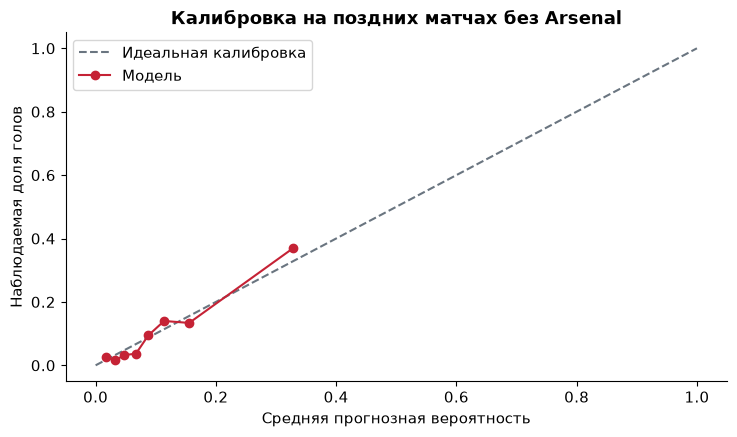

In [9]:
FEATURES = ["distance","angle","head_body","direct_fk"]
assert not ({"goal","penalty","own_goal","xg"} & set(FEATURES))
other_matches = matches[matches.team_id!=ARSENAL].drop_duplicates("match_id")
other_matches = other_matches[~other_matches.match_id.isin(ars.match_id)].sort_values(["date","match_id"])
assert len(other_matches)==342
cut = int(len(other_matches)*0.8)
train_ids=set(other_matches.iloc[:cut].match_id)
test_ids=set(other_matches.iloc[cut:].match_id)
train_ids -= set(unmatched_goal_matches)
test_ids -= set(unmatched_goal_matches)
assert train_ids.isdisjoint(test_ids)
assert not (train_ids|test_ids)&set(ars.match_id)
nonpen = shots[~shots.penalty & ~shots.own_goal].copy()
train=nonpen[nonpen.match_id.isin(train_ids)]
test=nonpen[nonpen.match_id.isin(test_ids)]
model=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,max_iter=1000,random_state=SEED))
model.fit(train[FEATURES],train.goal)
test_prob=model.predict_proba(test[FEATURES])[:,1]
baseline_prob=np.full(len(test),train.goal.mean())
quality=[]
for name,pred in [("Постоянная вероятность",baseline_prob),("Логистическая регрессия",test_prob)]:
    quality.append({"model":name,"brier":brier_score_loss(test.goal,pred),
        "log_loss":log_loss(test.goal,pred),"roc_auc":roc_auc_score(test.goal,pred)})
quality=pd.DataFrame(quality)
shots["xg"]=np.nan
mask=~shots.penalty & ~shots.own_goal
shots.loc[mask,"xg"]=model.predict_proba(shots.loc[mask,FEATURES])[:,1]
assert shots.loc[mask,"xg"].between(0,1).all()
print("Матчи train/test:",len(train_ids),len(test_ids),"| удары:",len(train),len(test))
display(quality.round(4))
display(pd.DataFrame({"feature":FEATURES,"standardized_coefficient":model[-1].coef_[0]}))
fig, ax=plt.subplots(figsize=(7.5,4.5))
observed,predicted=calibration_curve(test.goal,test_prob,n_bins=8,strategy="quantile")
ax.plot([0,1],[0,1],color=GRAY,linestyle="--",label="Идеальная калибровка")
ax.plot(predicted,observed,"o-",color=RED,label="Модель")
ax.set(xlabel="Средняя прогнозная вероятность",ylabel="Наблюдаемая доля голов",
       title="Калибровка на поздних матчах без Arsenal")
ax.legend();fig.tight_layout();fig.savefig(FIG/"01_calibration.png",dpi=180);plt.show()


### Интерпретация проверки модели

На 69 отложенных матчах (1522 ударов) Brier снизился с 0.0946 до 0.0793, log loss — с 0.3376 до 0.2782. Поэтому геометрическая модель полезнее константы на этой проверке. ROC AUC 0.793 описывает ранжирование, а калибровка показывает точность вероятностей. Это не доказывает точность каждого xG Arsenal.

Исходный split: 273 ранних / 69 поздних матчей без Arsenal. После исключения одного матча с неполным событием гола обучение использует 272 матча. Границу split не переносили.

## 6. Парное сравнение и три основные проверки

Пара — два матча Arsenal с одним соперником. Интервалы отражают вариативность этих 19 пар,
а не полную неопределённость параметров xG-модели. Поэтому интерпретация условна относительно выбранной модели.
Двусторонние p-value позволяют обнаружить и противоположное направление. Порог 0,05 после Holm не заменяет размер эффекта.


,id,title,difference,low,high,p,p_holm,verdict
0,H1,Баланс качества моментов,-0.7933,-1.4374,-0.1736,0.0239,0.0717,Не подтверждена после Holm
1,H2,Реализация собственных ударов,-0.9675,-1.7539,-0.0615,0.0433,0.0866,Не подтверждена после Holm
2,H3,Удар после неудачной передачи,0.6175,-0.1915,1.3980,0.1580,0.1580,Не подтверждена после Holm


,matches,points,gf,ga,npxg,npxga,np_goals,np_ga,finishing,defensive_residual,shots,shots_against,pass_share,pass_completion
home,,,,,,,,,,,,,,
False,19,16,20,31,23.528,20.950,18.0,27.0,-5.528,6.050,240.0,223.0,0.615,0.857
True,19,47,54,20,38.145,20.493,51.0,19.0,12.855,-1.493,328.0,174.0,0.643,0.865


,xg_balance,finishing,pass_share,shots,shots_against
outcome,,,,,
Ничья,0.227,-0.250,0.610,13.500,11.167
Победа,1.031,0.862,0.655,17.474,9.105
Поражение,-0.055,-0.581,0.600,11.923,12.077


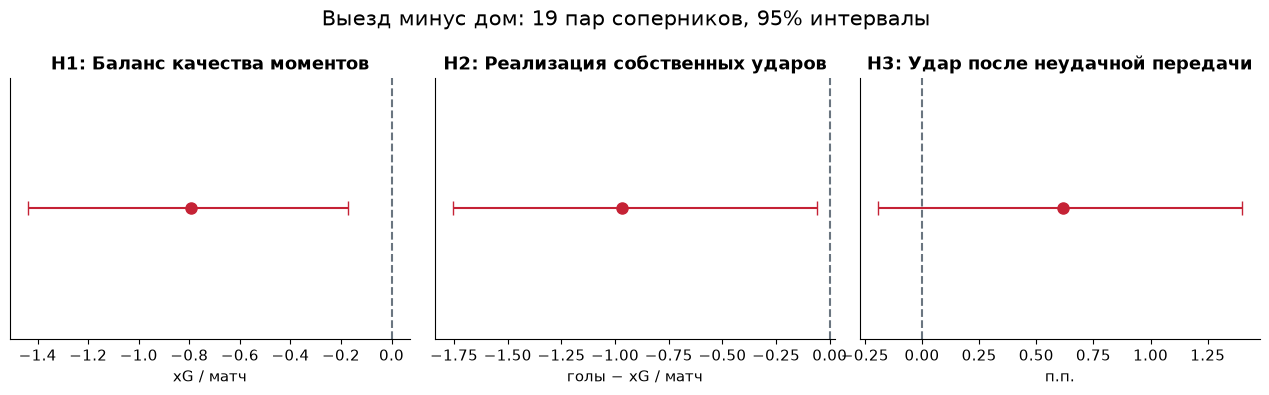

In [10]:
nonpen = shots[~shots.penalty & ~shots.own_goal].copy()
agg=nonpen.groupby(["match_id","team_id"]).agg(npxg=("xg","sum"),np_goals=("goal","sum"),shots=("id","size")).reset_index()
matches=matches.merge(agg,on=["match_id","team_id"],how="left")
matches[["npxg","np_goals","shots"]]=matches[["npxg","np_goals","shots"]].fillna(0)
opp=agg.rename(columns={"team_id":"opponent_id","npxg":"npxga","np_goals":"np_ga","shots":"shots_against"})
matches=matches.merge(opp,on=["match_id","opponent_id"],how="left")
matches[["npxga","np_ga","shots_against"]]=matches[["npxga","np_ga","shots_against"]].fillna(0)
matches["xg_balance"]=matches.npxg-matches.npxga
matches["finishing"]=matches.np_goals-matches.npxg
matches["defensive_residual"]=matches.np_ga-matches.npxga
matches["xg_per_shot"]=matches.npxg/matches.shots.replace(0,np.nan)
ars=matches[matches.team_id==ARSENAL].copy().sort_values("date")
for horizon in [10,15,20]:
    totals=windows[windows.horizon==horizon].groupby("match_id").agg(
        attempts=("start","size"),hits=("hit","sum"))
    ars=ars.merge(totals.rename(columns={"attempts":f"attempts_{horizon}","hits":f"hits_{horizon}"}),
        left_on="match_id",right_index=True,how="left")
    ars[f"risk_{horizon}"]=100*ars[f"hits_{horizon}"]/ars[f"attempts_{horizon}"].replace(0,np.nan)

def paired_stats(frame,metric,seed=SEED):
    pivot=frame.pivot(index="opponent_id",columns="home",values=metric).dropna()
    if not {False,True}.issubset(pivot.columns) or len(pivot)<2:
        return {"n":len(pivot),"difference":None,"low":None,"high":None,"p":None}
    delta=(pivot[False]-pivot[True]).to_numpy(float)
    rng=np.random.default_rng(seed)
    boot=rng.choice(delta,size=(BOOTSTRAPS,len(delta)),replace=True).mean(axis=1)
    null=(rng.choice([-1,1],size=(19999,len(delta)))*delta).mean(axis=1)
    return {"n":len(delta),"difference":float(delta.mean()),
        "low":float(np.quantile(boot,.025)),"high":float(np.quantile(boot,.975)),
        "p":float((1+(np.abs(null)>=abs(delta.mean())-1e-12).sum())/(len(null)+1))}

def holm_adjust(p_values):
    p=np.asarray(p_values,float);order=np.argsort(p);result=np.empty(len(p))
    running=0
    for rank,i in enumerate(order):
        running=max(running,(len(p)-rank)*p[i]);result[i]=min(1,running)
    return result

assert np.allclose(holm_adjust([.01,.04,.03]),[.03,.06,.06])
assert paired_stats(pd.DataFrame(columns=["opponent_id","home","value"]),"value")["difference"] is None
assert np.isclose(np.rad2deg(np.arctan2(7.32*11,11**2-3.66**2)),36.808,atol=.01)
hypotheses=[
    {"id":"H1","title":"Баланс качества моментов","metric":"xg_balance","unit":"xG / матч","expected":-1},
    {"id":"H2","title":"Реализация собственных ударов","metric":"finishing","unit":"голы − xG / матч","expected":-1},
    {"id":"H3","title":"Удар после неудачной передачи","metric":"risk_15","unit":"п.п.","expected":1}]
for h in hypotheses:h.update(paired_stats(ars,h["metric"]))
adjusted=holm_adjust([h["p"] for h in hypotheses])
for h,p in zip(hypotheses,adjusted):
    h["p_holm"]=float(p)
    h["supported"]=bool(p<.05 and h["difference"]*h["expected"]>0)
    h["verdict"]="Поддерживается" if h["supported"] else "Не подтверждена после Holm"
display(pd.DataFrame(hypotheses)[["id","title","difference","low","high","p","p_holm","verdict"]].round(4))
summary=ars.groupby("home").agg(matches=("match_id","size"),points=("points","sum"),
    gf=("gf","sum"),ga=("ga","sum"),npxg=("npxg","sum"),npxga=("npxga","sum"),
    np_goals=("np_goals","sum"),np_ga=("np_ga","sum"),finishing=("finishing","sum"),
    defensive_residual=("defensive_residual","sum"),shots=("shots","sum"),
    shots_against=("shots_against","sum"),pass_share=("pass_share","mean"),
    pass_completion=("pass_completion","mean"))
display(summary.round(3))
ars["outcome"]=np.where(ars.points==3,"Победа",np.where(ars.points==1,"Ничья","Поражение"))
display(ars.groupby("outcome")[["xg_balance","finishing","pass_share","shots","shots_against"]].mean().round(3))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,h in zip(axes,hypotheses):
    ax.errorbar(h["difference"],0,xerr=[[h["difference"]-h["low"]],[h["high"]-h["difference"]]],
        fmt="o",color=RED,capsize=5,markersize=8)
    ax.axvline(0,color=GRAY,ls="--");ax.set(yticks=[],xlabel=h["unit"],title=h["id"]+": "+h["title"])
fig.suptitle("Выезд минус дом: 19 пар соперников, 95% интервалы",fontsize=15)
fig.tight_layout();fig.savefig(FIG/"02_hypotheses.png",dpi=180);plt.show()


### Ответ: с какими различиями связан разрыв результатов?

Основные проверки показывают снижение созданного xG и реализации на выезде. После Holm ни одна из трёх гипотез не подтверждена при 0,05. Отсутствие значимости не доказывает отсутствие эффекта.

Сравнение только созданного и допущенного xG не описывает весь разрыв голов. В разделе 8а ниже рассчитаны все четыре компонента разрыва, включая обе реализации, и проверен точный переход к фактической разнице голов. Это бухгалтерское тождество, а не причинное объяснение потерянных очков.


## 7. Разрезы и устойчивость

Проверяем эпизоды при равном счёте и 11×11; для H3 контекст фиксируется в момент неудачной передачи.
Показатели подвыборок нормированы по их собственным наблюдаемым передачам, а не по всему матчу.
Силу соперника определяем описательно по очкам в остальных матчах сезона без Arsenal: верхняя/нижняя половина.
Это ретроспективная характеристика, не признак прогнозной модели.
Доля передач — прокси активности с мячом, не измеренный процент владения по времени.


,context,metric,n,difference,low,high,p
0,all,xg_balance,19,-0.7933,-1.4374,-0.1736,0.0239
1,all,finishing,19,-0.9675,-1.7539,-0.0615,0.0433
2,all,risk_10,19,0.0135,-0.6060,0.5751,0.9640
3,all,risk_15,19,0.6175,-0.1915,1.3980,0.1580
4,all,risk_20,19,0.7541,-0.2996,1.9121,0.2148
5,eleven,xg_balance,19,-0.8061,-1.3629,-0.2482,0.0130
6,eleven,finishing,19,-1.0899,-1.8691,-0.2254,0.0206
7,eleven,risk_10,19,0.2524,-0.5655,1.2145,0.6619
8,eleven,risk_15,19,0.7997,-0.1545,1.7664,0.1329
9,eleven,risk_20,19,0.7905,-0.3046,2.0021,0.2147


points  xg_balance  finishing  risk_15
opponent_group   home                                         
Верхняя половина False   1.100       0.152     -0.174    3.013
                 True    2.000       0.757      0.900    2.189
Нижняя половина  False   0.556       0.118     -0.421    2.441
                 True    3.000       1.120      0.428    2.053

points  xg_balance  finishing  risk_15
season_half home                                         
Туры 1–19   False   1.000       0.453     -0.389    2.762
            True    2.500       1.201      0.210    2.470
Туры 20–38  False   0.700      -0.150     -0.202    2.724
            True    2.444       0.627      1.195    1.741

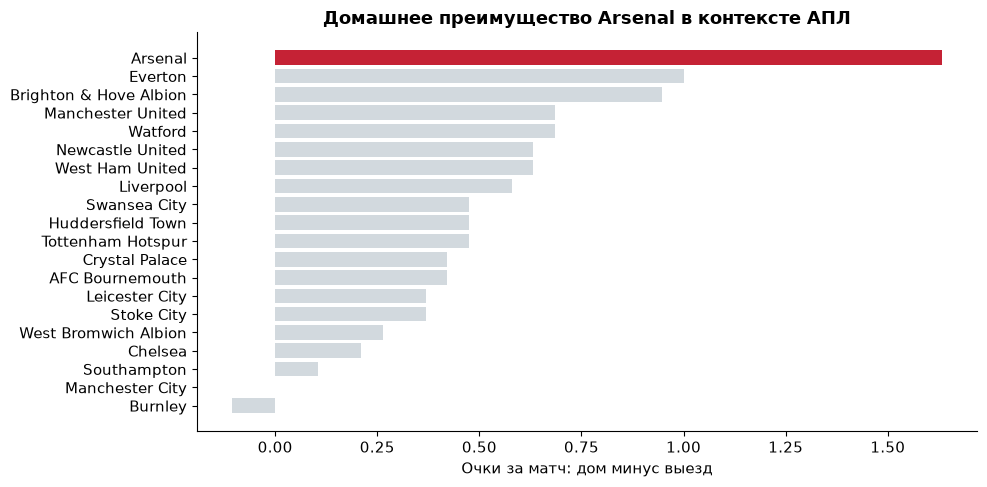

In [11]:
other=matches[matches.team_id!=ARSENAL]
strength=other[~other.match_id.isin(ars.match_id)].groupby("team_id").points.sum().sort_values(ascending=False)
strong=set(strength.index[:10])
ars["opponent_group"]=np.where(ars.opponent_id.isin(strong),"Верхняя половина","Нижняя половина")
ars["season_half"]=np.where(ars.week<=19,"Туры 1–19","Туры 20–38")
context_rows=[]
for context in ["all","eleven","level"]:
    s=nonpen.copy()
    w=windows.copy()
    if context=="eleven":
        s=s[s.eleven_v_eleven];w=w[w.eleven_v_eleven]
    elif context=="level":
        s=s[s.eleven_v_eleven & (s.score_diff==0)]
        w=w[w.eleven_v_eleven & (w.score_diff==0)]
    frame=ars[["match_id","opponent_id","home"]].copy()
    own=s[s.team_id==ARSENAL].groupby("match_id").agg(xgf=("xg","sum"),goals=("goal","sum"))
    against=s[s.opponent_id==ARSENAL].groupby("match_id").xg.sum()
    frame=frame.merge(own,left_on="match_id",right_index=True,how="left").fillna({"xgf":0,"goals":0})
    frame["xga"]=frame.match_id.map(against).fillna(0)
    frame["xg_balance"]=frame.xgf-frame.xga
    frame["finishing"]=frame.goals-frame.xgf
    for horizon in [10,15,20]:
        total=w[w.horizon==horizon].groupby("match_id").agg(n=("start","size"),hits=("hit","sum"))
        rate=100*total.hits/total.n
        frame[f"risk_{horizon}"]=frame.match_id.map(rate)
    for metric in ["xg_balance","finishing","risk_10","risk_15","risk_20"]:
        context_rows.append({"context":context,"metric":metric,**paired_stats(frame,metric)})
contexts=pd.DataFrame(context_rows)
display(contexts.round(4))
display(ars.groupby(["opponent_group","home"])[["points","xg_balance","finishing","risk_15"]].mean().round(3))
display(ars.groupby(["season_half","home"])[["points","xg_balance","finishing","risk_15"]].mean().round(3))
team_home=matches.groupby(["team_id","team","home"]).agg(ppg=("points","mean"),xgd=("xg_balance","mean")).reset_index()
league_gaps=[]
for tid,frame in team_home.groupby("team_id"):
    p=frame.set_index("home")
    league_gaps.append({"team":team_names[tid],"team_id":int(tid),
        "points_gap":float(p.loc[True,"ppg"]-p.loc[False,"ppg"]),
        "xg_gap":float(p.loc[True,"xgd"]-p.loc[False,"xgd"])})
league_gaps=sorted(league_gaps,key=lambda r:r["points_gap"],reverse=True)
fig,ax=plt.subplots(figsize=(10,5))
ax.barh([r["team"] for r in league_gaps][::-1],[r["points_gap"] for r in league_gaps][::-1],
    color=[RED if r["team_id"]==ARSENAL else "#D2D9DE" for r in league_gaps][::-1])
ax.set(xlabel="Очки за матч: дом минус выезд",title="Домашнее преимущество Arsenal в контексте АПЛ")
fig.tight_layout();fig.savefig(FIG/"03_league_context.png",dpi=180);plt.show()


### Контекстные суммы: предварительное описание

Таблица выше сохраняет первоначальные суммы эпизодов при выбранном состоянии. Они зависят от числа минут в состоянии. В разделе 8а добавлены экспозиция, xG на 90 минут состояния и чувствительность к длительности тайма. Исходные Holm p не переносятся на эти новые метрики.

Сила соперников и половины сезона остаются ретроспективными разведочными разрезами. Доля передач — прокси активности, не измеренное владение по времени. Ни один такой разрез не является контролируемым экспериментом.


## 8. Карты ударов и парные матчи

Каждая точка — реальный непенальтийный удар Arsenal; направление атаки приведено к правым воротам.
Размер точки соответствует оценке xG, заполнение — голу. На картах нет позиций остальных игроков:
это события с мячом, а не непрерывная реконструкция матча.


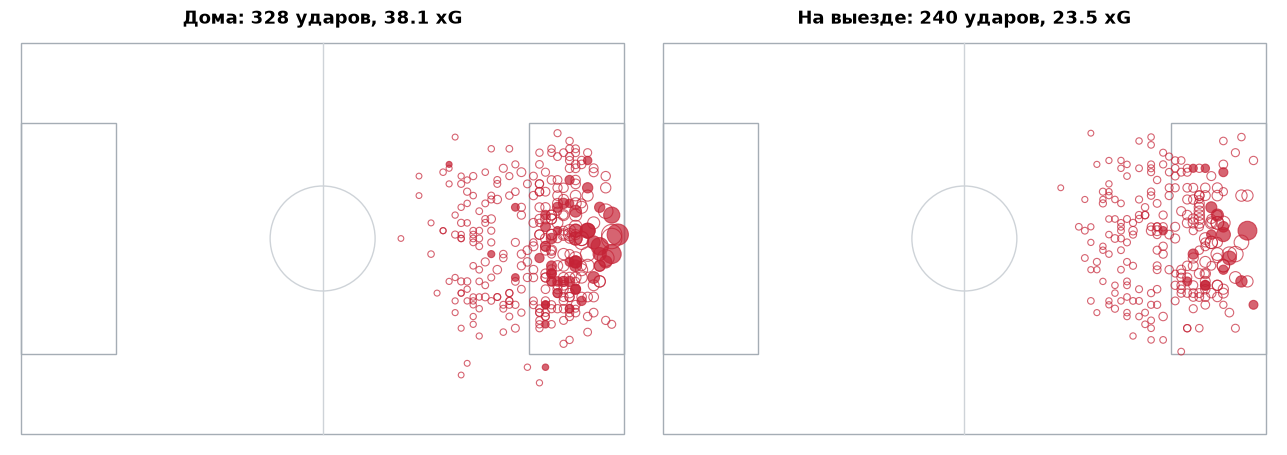

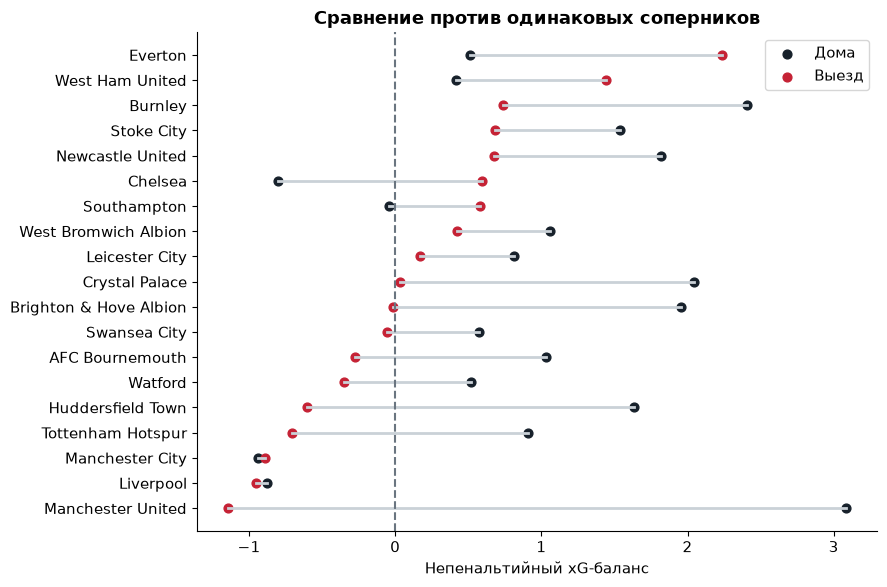

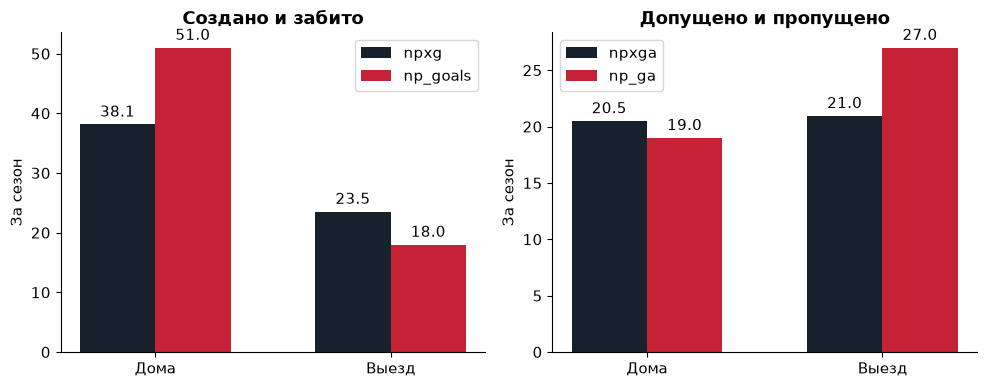

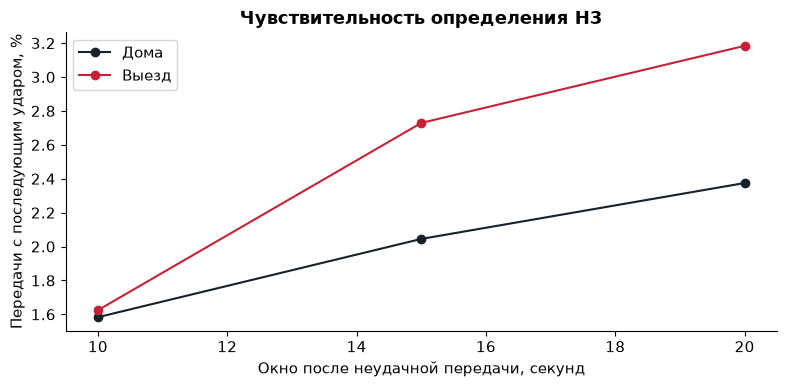

In [12]:
def pitch(ax):
    from matplotlib.patches import Rectangle,Arc
    ax.add_patch(Rectangle((0,0),105,68,fill=False,edgecolor="#A5ADB5",lw=1))
    ax.plot([52.5,52.5],[0,68],color="#CED3D8",lw=1)
    ax.add_patch(plt.Circle((52.5,34),9.15,fill=False,color="#CED3D8"))
    for x in [0,88.5]:
        ax.add_patch(Rectangle((x,13.84),16.5,40.32,fill=False,edgecolor="#A5ADB5"))
    ax.set(xlim=(-2,107),ylim=(-2,70),aspect="equal",xticks=[],yticks=[])
    for spine in ax.spines.values():spine.set_visible(False)
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for home,ax in zip([True,False],axes):
    s=shots[(shots.team_id==ARSENAL)&(~shots.penalty)&(~shots.own_goal)&(shots.home==home)]
    pitch(ax)
    for goal in [0,1]:
        q=s[s.goal==goal]
        ax.scatter(q.x*1.05,q.y*.68,s=15+q.xg*240,facecolors=RED if goal else "none",
                   edgecolors=RED,alpha=.7,lw=.8)
    ax.set_title(("Дома" if home else "На выезде")+f": {len(s)} ударов, {s.xg.sum():.1f} xG")
fig.tight_layout();fig.savefig(FIG/"04_shot_maps.png",dpi=180);plt.show()
pair=ars.pivot(index="opponent",columns="home",values="xg_balance").sort_values(False)
fig,ax=plt.subplots(figsize=(9,6))
for i,(opp,row) in enumerate(pair.iterrows()):
    ax.plot([row[True],row[False]],[i,i],color="#CAD1D7",lw=2)
ax.scatter(pair[True],range(len(pair)),label="Дома",color=INK,s=40)
ax.scatter(pair[False],range(len(pair)),label="Выезд",color=RED,s=40)
ax.axvline(0,color=GRAY,ls="--");ax.set(yticks=range(len(pair)),yticklabels=pair.index,
    xlabel="Непенальтийный xG-баланс",title="Сравнение против одинаковых соперников")
ax.legend();fig.tight_layout();fig.savefig(FIG/"05_opponent_pairs.png",dpi=180);plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,cols,title in [(axes[0],["npxg","np_goals"],"Создано и забито"),
                     (axes[1],["npxga","np_ga"],"Допущено и пропущено")]:
    x=np.arange(2)
    for j,col in enumerate(cols):
        values=[float(summary.loc[h,col]) for h in [True,False]]
        bars=ax.bar(x+(j-.5)*.32,values,width=.32,color=INK if j==0 else RED,label=col)
        ax.bar_label(bars,fmt="%.1f",padding=3)
    ax.set(xticks=x,xticklabels=["Дома","Выезд"],title=title,ylabel="За сезон")
    ax.legend()
fig.tight_layout();fig.savefig(FIG/"06_finishing.png",dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for home,color,label in [(True,INK,"Дома"),(False,RED,"Выезд")]:
    frame=ars[ars.home==home]
    vals=[100*frame[f"hits_{h}"].sum()/frame[f"attempts_{h}"].sum() for h in [10,15,20]]
    ax.plot([10,15,20],vals,"o-",color=color,label=label)
ax.set(xlabel="Окно после неудачной передачи, секунд",ylabel="Передачи с последующим ударом, %",
       title="Чувствительность определения H3");ax.legend()
fig.tight_layout();fig.savefig(FIG/"07_window_sensitivity.png",dpi=180);plt.show()


## 8а. Доработка по ревью: механизм, экспозиция, разложение и устойчивость

Эти задачи сформулированы после первоначальных результатов и являются **разведочными**. Мы не меняем H1–H3 и не выбираем новый основной тест по выгодному p-value.

Механизм: доставки передачей из атакующей трети вне штрафной в штрафную, навесы против остальных передач. В знаменатель входят все передачи из выбранной зоны, а не только завершившиеся ударом. Каждая доставка может иметь отрицательное продолжение. Удар относим только к последней подходящей доставке за 15 секунд в том же тайме, без остановки или подтверждённого контроля соперника.

Экспозиция — минуты матчевых часов с остановками, без перерыва. Конец тайма оценивается как максимум 45 минут и последнего события. Это приближение; отдельно проверяем приведение каждого тайма к 45 минутам. Нормировка учитывает знаменатель, но не устраняет смешение по счёту, сопернику и поведению команд.

Сначала показываем расчёты и интервалы, затем формируем предложение тренеру. Дополнительная регрессия только с расстоянием и углом проверяет устойчивость основной модели на том же разделении матчей.


### Экспозиция состояний: суммы и интенсивности

,context,home,matches,minutes,nominal_minutes,xgf,xga,xgf_per90,xga_per90,balance_per90,nominal_balance_per90
0,all,False,19,1822.195,1710.000,23.528,20.950,1.162,1.035,0.127,0.136
1,all,True,19,1821.154,1710.000,38.145,20.493,1.885,1.013,0.872,0.929
2,eleven,False,19,1703.669,1602.482,21.063,19.517,1.113,1.031,0.082,0.087
3,eleven,True,19,1793.671,1685.683,37.355,20.493,1.874,1.028,0.846,0.900
4,level,False,19,915.606,870.614,12.943,10.701,1.272,1.052,0.220,0.232
5,level,True,19,537.197,505.926,11.092,6.888,1.858,1.154,0.704,0.748


,context,metric,n,difference,low,high
0,all,xgf_per90,19,-0.720,-1.216,-0.334
1,all,xga_per90,19,0.026,-0.294,0.328
2,all,balance_per90,19,-0.746,-1.346,-0.164
3,all,nominal_balance_per90,19,-0.793,-1.437,-0.174
4,eleven,xgf_per90,19,-0.792,-1.336,-0.383
5,eleven,xga_per90,19,0.039,-0.311,0.379
6,eleven,balance_per90,19,-0.830,-1.451,-0.222
7,eleven,nominal_balance_per90,19,-0.886,-1.548,-0.237
8,level,xgf_per90,19,-1.421,-2.242,-0.684
9,level,xga_per90,19,0.341,-0.523,1.218


Агрегированные интенсивности и среднее по парам — разные оценки. При малом числе минут индивидуальная скорость нестабильна. Ниже — бутстрэп агрегированных интенсивностей по тем же парам и чувствительность среднего к минимуму 10 минут состояния в обоих матчах.

,context,metric,n,difference,low,high
0,all,xgf_per90,19,-0.723,-1.227,-0.332
1,all,xga_per90,19,0.022,-0.296,0.324
2,all,xg_balance_per90,19,-0.745,-1.346,-0.162
3,eleven,xgf_per90,19,-0.762,-1.235,-0.405
4,eleven,xga_per90,19,0.003,-0.333,0.322
5,eleven,xg_balance_per90,19,-0.764,-1.325,-0.215
6,level,xgf_per90,19,-0.586,-1.454,-0.025
7,level,xga_per90,19,-0.102,-0.584,0.466
8,level,xg_balance_per90,19,-0.484,-1.635,0.382


,context,minimum_minutes_both_matches,n,difference,low,high
0,all,10,19,-0.746,-1.346,-0.164
1,eleven,10,19,-0.830,-1.451,-0.222
2,level,10,11,-0.697,-1.863,0.332


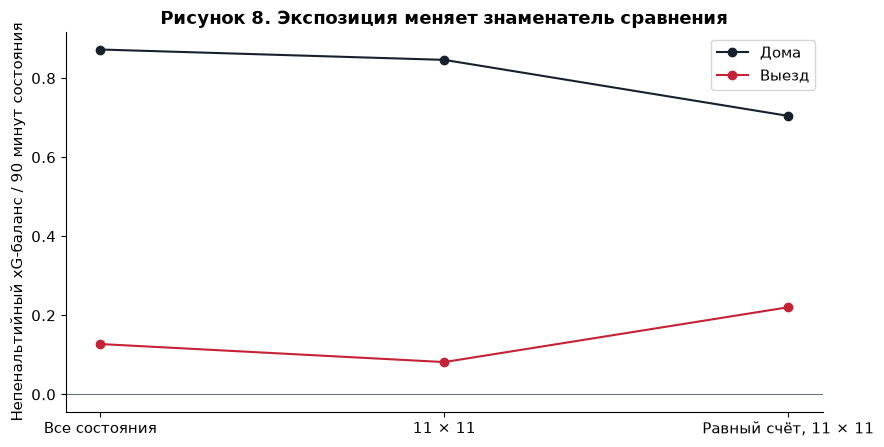

Источник рисунка 8: Wyscout, собственные расчёты. Минуты включают остановки. График показывает агрегированные интенсивности; интервалы выше относятся к парным различиям.

### Доставка в штрафную: все попытки, включая отрицательные примеры

,route,home,opportunities,attempts,known_accuracy,successes,hits,xg,xg_alternative,entries_per100_opportunities,completion_pct,shot_pct,xg_per100_entries,alternative_xg_per100_entries
0,cross,False,2841.0,143.0,143.0,62.0,26.0,4.089,4.516,5.033,43.357,18.182,2.859,3.158
1,cross,True,3109.0,132.0,132.0,43.0,19.0,4.143,4.224,4.246,32.576,14.394,3.139,3.200
2,other,False,2841.0,311.0,311.0,188.0,50.0,6.089,5.414,10.947,60.450,16.077,1.958,1.741
3,other,True,3109.0,366.0,366.0,247.0,95.0,13.204,11.340,11.772,67.486,25.956,3.608,3.098


,route,metric,n,difference,low,high
0,cross,entries_per100_opportunities,19,0.874,-0.426,2.489
1,cross,completion_pct,18,11.306,-4.081,26.635
2,cross,shot_pct,18,9.029,-3.740,23.303
3,cross,xg_per100_entries,18,0.373,-2.333,2.867
4,cross,alternative_xg_per100_entries,18,1.023,-1.807,3.894
5,other,entries_per100_opportunities,19,-0.488,-3.572,2.262
6,other,completion_pct,19,-8.166,-14.648,-1.938
7,other,shot_pct,19,-11.961,-17.760,-6.223
8,other,xg_per100_entries,19,-1.845,-2.734,-1.027
9,other,alternative_xg_per100_entries,19,-1.542,-2.268,-0.859


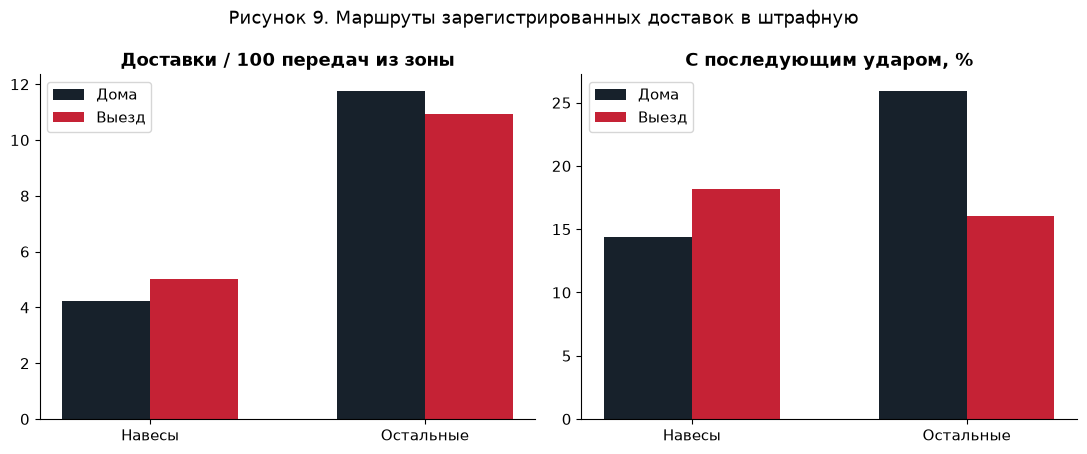

Источник рисунка 9: Wyscout, собственные расчёты. Разведочный анализ. Знаменатель первого графика включает передачи без входа в штрафную; второго — все зарегистрированные доставки.

### Полное разложение разрыва разницы голов

,key,label,value
0,creation,Меньше создано Arsenal,14.617
1,allowed,Больше допущено,0.457
2,own_finishing,Изменение реализации Arsenal,18.383
3,opponent_finishing,Изменение реализации соперников,7.543


{'direction': 'Дом минус выезд',
 'components': [{'key': 'creation',
   'label': 'Меньше создано Arsenal',
   'value': 14.616668095949208},
  {'key': 'allowed', 'label': 'Больше допущено', 'value': 0.45692288728880115},
  {'key': 'own_finishing',
   'label': 'Изменение реализации Arsenal',
   'value': 18.38333190405079},
  {'key': 'opponent_finishing',
   'label': 'Изменение реализации соперников',
   'value': 7.5430771127112}],
 'nonpenalty_goal_difference_gap': 41.0,
 'penalty_gap': 5,
 'own_goal_gap': -1,
 'actual_goal_difference_gap': 45.0,
 'penalty_goal_difference': {True: 2, False: -3},
 'own_goal_difference': {True: 0, False: 1},
 'claim': 'Модельное бухгалтерское разложение, не причинные вклады и не распределение потерянных очков'}

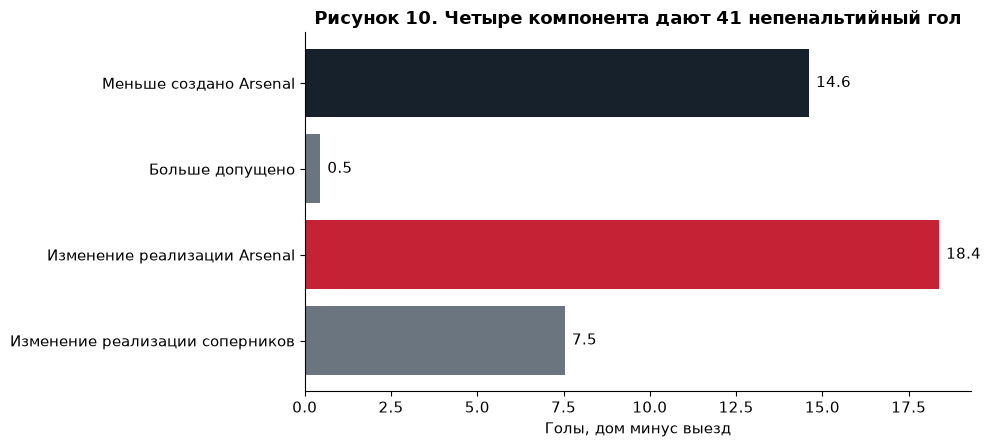

Источник рисунка 10: Wyscout, основная xG-модель. Это точное тождество для выбранной модели; самая большая составляющая здесь — изменение собственной реализации, а не доказанный тактический механизм.

### Устойчивость к спецификации модели

,model,brier,log_loss,roc_auc
0,Логистическая регрессия,0.0793,0.2782,0.7935
1,Регрессия: расстояние и угол,0.0818,0.2862,0.7737


,metric,primary_difference,alternative_difference,alternative_low,alternative_high,n,same_direction
0,xg_balance,-0.7933,-0.7438,-1.3110,-0.181,19,True
1,finishing,-0.9675,-1.0488,-1.8096,-0.200,19,True


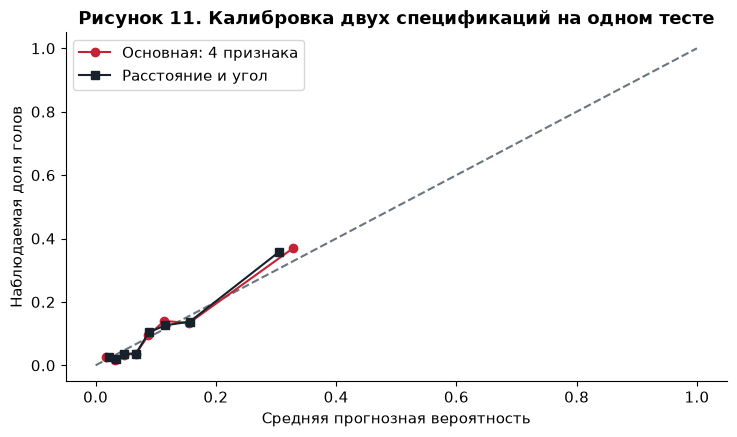

Источник рисунка 11: Wyscout, поздние 69 матчей без Arsenal. Стандартизация и коэффициенты каждой модели обучены только на ранней части.

### Интерпретация доработки

После доставок без навеса удар следует в **26.0% дома и 16.1% на выезде**. Средняя парная разница **-11.96 п.п.**, 95% ДИ [-17.76; -6.22]. Оценка xG на 100 таких доставок снижается в обеих спецификациях. Частота самих доставок имеет более неопределённое различие. Это мотивирует проверять приём и следующее решение после доставки, а не считать доказанной необходимость чаще использовать определённый маршрут.

Анализ проведён после первоначальных результатов; интервалы не скорректированы на множество разведочных сравнений. Ситуации и давление могут различаться, поэтому даже интервал без нуля не доказывает причинный механизм.

Все четыре бухгалтерских компонента дают **41**: добавление разницы пенальти (+5) и автоголов (-1) даёт фактические **45**. Наибольшая модельная составляющая — изменение реализации Arsenal. Не приписываем её целиком мастерству или психологии.

Нормировка по экспозиции меняет величину контекстного различия; сравнение одних сумм при равном счёте недостаточно. Парные оценки и агрегированные интенсивности показаны отдельно. Основные H1–H3 и их Holm p сохранены.

In [13]:
# Команда: только предоставленные имена; выполненные человеческие проверки не заявляются.
team = {'group':'AAI-2501M','members':['Faizolla Amanbek','Bolatov Madiyar',
    'Akhmedov Adilet','Syzdykov Sanzhar']}
route_labels = {'cross':'Навесы','other':'Остальные передачи'}

# 1. Экспозиция: каждое состояние занимает интервал матчевых часов.
exposure_rows = []
interval_rows = []
for match in ars.to_dict('records'):
    mid = match['match_id']
    raw = match_map[mid]
    td = {int(k):v for k,v in raw['teamsData'].items()}
    home_id = next(k for k,v in td.items() if v['side']=='home')
    away_id = next(k for k,v in td.items() if v['side']=='away')
    expected = {k:int(v['score']) for k,v in td.items()}
    intervals = state_exposure(grouped[mid],home_id,away_id,ARSENAL,expected)
    assert {x['period'] for x in intervals}=={'1H','2H'}
    assert np.isclose(sum(x['nominal_seconds'] for x in intervals),5400)
    interval_rows.extend({'match_id':mid,**x} for x in intervals)
    s = nonpen[nonpen.match_id==mid]
    for context in ['all','eleven','level']:
        chosen = [x for x in intervals if context=='all' or
            (x['eleven_v_eleven'] and (context!='level' or x['score_diff']==0))]
        selected = s if context=='all' else s[s.eleven_v_eleven]
        if context=='level':selected=selected[selected.score_diff==0]
        minutes = sum(x['seconds'] for x in chosen)/60
        nominal_minutes = sum(x['nominal_seconds'] for x in chosen)/60
        own = selected[selected.team_id==ARSENAL]
        against = selected[selected.opponent_id==ARSENAL]
        xgf, xga = float(own.xg.sum()),float(against.xg.sum())
        exposure_rows.append({'match_id':mid,'opponent_id':match['opponent_id'],
            'home':match['home'],'context':context,'minutes':minutes,
            'nominal_minutes':nominal_minutes,'xgf':xgf,'xga':xga,
            'xg_balance':xgf-xga,'xgf_per90':safe_rate(xgf,minutes,90),
            'xga_per90':safe_rate(xga,minutes,90),
            'balance_per90':safe_rate(xgf-xga,minutes,90),
            'nominal_balance_per90':safe_rate(xgf-xga,nominal_minutes,90)})
exposure_frame = pd.DataFrame(exposure_rows)
exposure_summary = []
exposure_effects = []
for context in ['all','eleven','level']:
    part = exposure_frame[exposure_frame.context==context]
    for is_home, frame in part.groupby('home'):
        minute, nominal = float(frame.minutes.sum()),float(frame.nominal_minutes.sum())
        gf,ga=float(frame.xgf.sum()),float(frame.xga.sum())
        exposure_summary.append({'context':context,'home':bool(is_home),'matches':len(frame),
            'minutes':minute,'nominal_minutes':nominal,'xgf':gf,'xga':ga,
            'xgf_per90':safe_rate(gf,minute,90),'xga_per90':safe_rate(ga,minute,90),
            'balance_per90':safe_rate(gf-ga,minute,90),
            'nominal_balance_per90':safe_rate(gf-ga,nominal,90)})
    for metric in ['xgf_per90','xga_per90','balance_per90','nominal_balance_per90']:
        stats=paired_stats(part,metric)
        # Разведочные интервалы, исходные Holm p не переносятся.
        stats.pop('p',None)
        exposure_effects.append({'context':context,'metric':metric,**stats})
pooled_exposure_effects=[]
short_exposure_sensitivity=[]
for context in ['all','eleven','level']:
    part=exposure_frame[exposure_frame.context==context]
    for metric in ['xgf','xga','xg_balance']:
        numerator=part.pivot(index='opponent_id',columns='home',values=metric)
        denominator=part.pivot(index='opponent_id',columns='home',values='minutes')
        ids=numerator.index.intersection(denominator.index)
        rng=np.random.default_rng(SEED);draw=rng.integers(0,len(ids),size=(BOOTSTRAPS,len(ids)))
        gf=numerator.loc[ids,True].to_numpy();ga=numerator.loc[ids,False].to_numpy()
        mh=denominator.loc[ids,True].to_numpy();ma=denominator.loc[ids,False].to_numpy()
        bootstrap=90*(ga[draw].sum(axis=1)/ma[draw].sum(axis=1)-gf[draw].sum(axis=1)/mh[draw].sum(axis=1))
        pooled_exposure_effects.append({'context':context,'metric':metric+'_per90',
            'n':len(ids),'difference':float(90*(ga.sum()/ma.sum()-gf.sum()/mh.sum())),
            'low':float(np.quantile(bootstrap,.025)),'high':float(np.quantile(bootstrap,.975))})
    duration=part.pivot(index='opponent_id',columns='home',values='minutes')
    eligible=duration.index[duration.min(axis=1)>=10]
    check=paired_stats(part[part.opponent_id.isin(eligible)],'balance_per90');check.pop('p',None)
    short_exposure_sensitivity.append({'context':context,'minimum_minutes_both_matches':10,**check})
state_exposure_result={'method':'Минуты матчевых часов, включая остановки, без перерыва',
    'half_end':'max(2700, время последнего события тайма)',
    'limitation':'Конец тайма приближённый; это не время мяча в игре. Нормировка не устраняет причинное смешение.',
    'rows':exposure_rows,'summary':exposure_summary,'effects':exposure_effects,
    'pooled_effects':pooled_exposure_effects,'short_exposure_sensitivity':short_exposure_sensitivity,
    'sensitivity':'nominal_balance_per90: каждый тайм пропорционально приведён к 45 минутам'}
display(Markdown('### Экспозиция состояний: суммы и интенсивности'))
display(pd.DataFrame(exposure_summary).round(3))
display(pd.DataFrame(exposure_effects).round(3))
display(Markdown('Агрегированные интенсивности и среднее по парам — разные оценки. '
    'При малом числе минут индивидуальная скорость нестабильна. Ниже — бутстрэп агрегированных интенсивностей '
    'по тем же парам и чувствительность среднего к минимуму 10 минут состояния в обоих матчах.'))
display(pd.DataFrame(pooled_exposure_effects).round(3))
display(pd.DataFrame(short_exposure_sensitivity).round(3))
fig,ax=plt.subplots(figsize=(9,4.6))
for is_home,color,label in [(True,INK,'Дома'),(False,RED,'Выезд')]:
    vals=[next(x for x in exposure_summary if x['context']==c and x['home']==is_home)['balance_per90'] for c in ['all','eleven','level']]
    ax.plot(['Все состояния','11 × 11','Равный счёт, 11 × 11'],vals,'o-',color=color,label=label)
ax.axhline(0,color=GRAY,lw=.8);ax.set(ylabel='Непенальтийный xG-баланс / 90 минут состояния',
    title='Рисунок 8. Экспозиция меняет знаменатель сравнения')
ax.legend();fig.tight_layout();fig.savefig(FIG/'08_state_exposure.png',dpi=180);plt.show()
display(Markdown('Источник рисунка 8: Wyscout, собственные расчёты. Минуты включают остановки. '
    'График показывает агрегированные интенсивности; интервалы выше относятся к парным различиям.'))

# 2. Входы в штрафную: знаменатель включает все передачи из выбранной зоны.
delivery_records = []
delivery_match_rows = []
xg_lookup = shots.set_index('id').xg.to_dict()
alt_features = ['distance','angle']
alternative_model=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,max_iter=1000,random_state=SEED))
alternative_model.fit(train[alt_features],train.goal)
alt_prob=alternative_model.predict_proba(test[alt_features])[:,1]
alt_shots = shots[~shots.penalty & ~shots.own_goal].copy()
alt_shots['xg']=alternative_model.predict_proba(alt_shots[alt_features])[:,1]
alt_xg_lookup=alt_shots.set_index('id').xg.to_dict()
for match in ars.to_dict('records'):
    mid=match['match_id']
    extracted=delivery_windows(grouped[mid],ARSENAL)
    attributed=[]
    for row in extracted['rows']:
        ids=row['shot_ids'];attributed.extend(ids)
        record={**row,'match_id':mid,'home':match['home'],'opponent_id':match['opponent_id'],
            'xg':sum(float(xg_lookup[i]) for i in ids),
            'xg_alternative':sum(float(alt_xg_lookup[i]) for i in ids),
            **states_by_match[mid][row['event_id']]}
        delivery_records.append(record)
    assert len(attributed)==len(set(attributed)), 'Один удар отнесён к двум доставкам'
    for route in ['cross','other']:
        rows=[x for x in extracted['rows'] if x['route']==route]
        attempts=len(rows);known=sum(x['accuracy_known'] for x in rows)
        successes=sum(x['success'] for x in rows);hits=sum(x['hit'] for x in rows)
        xg=sum(float(xg_lookup[i]) for x in rows for i in x['shot_ids'])
        axg=sum(float(alt_xg_lookup[i]) for x in rows for i in x['shot_ids'])
        delivery_match_rows.append({'match_id':mid,'opponent_id':match['opponent_id'],
            'home':match['home'],'route':route,'opportunities':extracted['opportunities'],
            'attempts':attempts,'known_accuracy':known,'successes':successes,'hits':hits,
            'xg':xg,'xg_alternative':axg,
            'entries_per100_opportunities':safe_rate(attempts,extracted['opportunities'],100),
            'completion_pct':safe_rate(successes,known,100),
            'shot_pct':safe_rate(hits,attempts,100),
            'xg_per100_entries':safe_rate(xg,attempts,100),
            'alternative_xg_per100_entries':safe_rate(axg,attempts,100)})
delivery_frame=pd.DataFrame(delivery_match_rows)
delivery_summary=[];delivery_effects=[]
for route in ['cross','other']:
    part=delivery_frame[delivery_frame.route==route]
    for is_home,frame in part.groupby('home'):
        totals={k:float(frame[k].sum()) for k in ['opportunities','attempts','known_accuracy','successes','hits','xg','xg_alternative']}
        delivery_summary.append({'route':route,'home':bool(is_home),**totals,
            'entries_per100_opportunities':safe_rate(totals['attempts'],totals['opportunities'],100),
            'completion_pct':safe_rate(totals['successes'],totals['known_accuracy'],100),
            'shot_pct':safe_rate(totals['hits'],totals['attempts'],100),
            'xg_per100_entries':safe_rate(totals['xg'],totals['attempts'],100),
            'alternative_xg_per100_entries':safe_rate(totals['xg_alternative'],totals['attempts'],100)})
    for metric in ['entries_per100_opportunities','completion_pct','shot_pct','xg_per100_entries','alternative_xg_per100_entries']:
        stats=paired_stats(part,metric);stats.pop('p',None)
        delivery_effects.append({'route':route,'metric':metric,**stats})
delivery_mechanism={'exploratory':True,'horizon':15,
    'definition':'Pass Arsenal: начало x ≥ 66.67 вне штрафной, конец внутри штрафной 16.5 × 40.32 м; поле 105 × 68 м',
    'denominator':'Все передачи Arsenal, начатые из атакующей трети вне штрафной, с двумя валидными координатами',
    'attribution':'До остановки, контроля соперника или 15 секунд; каждый непенальтийный удар относится к последней подходящей доставке',
    'limitation':'Конец неудачной передачи не устанавливает намерение игрока. Наблюдаемая последовательность не доказывает пользу маршрута.',
    'summary':delivery_summary,'effects':delivery_effects,'matches':delivery_match_rows,
    'deliveries':delivery_records,'unattributed_shots':int(len(nonpen[nonpen.team_id==ARSENAL])-sum(len(x['shot_ids']) for x in delivery_records))}
display(Markdown('### Доставка в штрафную: все попытки, включая отрицательные примеры'))
display(pd.DataFrame(delivery_summary).round(3))
display(pd.DataFrame(delivery_effects).round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4.6))
for ax,metric,title in zip(axes,['entries_per100_opportunities','shot_pct'],
    ['Доставки / 100 передач из зоны','С последующим ударом, %']):
    for j,(is_home,color,label) in enumerate([(True,INK,'Дома'),(False,RED,'Выезд')]):
        vals=[next(x for x in delivery_summary if x['route']==route and x['home']==is_home)[metric] for route in ['cross','other']]
        ax.bar(np.arange(2)+(j-.5)*.32,vals,width=.32,color=color,label=label)
    ax.set(xticks=[0,1],xticklabels=['Навесы','Остальные'],title=title);ax.legend()
fig.suptitle('Рисунок 9. Маршруты зарегистрированных доставок в штрафную')
fig.tight_layout();fig.savefig(FIG/'09_delivery_routes.png',dpi=180);plt.show()
display(Markdown('Источник рисунка 9: Wyscout, собственные расчёты. Разведочный анализ. '
    'Знаменатель первого графика включает передачи без входа в штрафную; второго — все зарегистрированные доставки.'))

# 3. Полный бухгалтерский мост: четыре компонента и отдельно пенальти/автоголы.
home=summary.loc[True];away=summary.loc[False]
components=[{'key':'creation','label':'Меньше создано Arsenal','value':float(home.npxg-away.npxg)},
    {'key':'allowed','label':'Больше допущено','value':float(away.npxga-home.npxga)},
    {'key':'own_finishing','label':'Изменение реализации Arsenal','value':float(home.finishing-away.finishing)},
    {'key':'opponent_finishing','label':'Изменение реализации соперников',
        'value':float(away.defensive_residual-home.defensive_residual)}]
nonpen_gap=float((home.np_goals-home.np_ga)-(away.np_goals-away.np_ga))
actual_gap=float((home.gf-home.ga)-(away.gf-away.ga))
penalty_gd={True:0,False:0};own_goal_gd={True:0,False:0}
for match in ars.to_dict('records'):
    for event in grouped[match['match_id']]:
        if event.get('subEventName')=='Penalty' and 101 in tags_of(event) and 102 not in tags_of(event):
            penalty_gd[match['home']]+=1 if event['teamId']==ARSENAL else -1
        if 102 in tags_of(event) and event['eventName']!='Save attempt':
            own_goal_gd[match['home']]+= -1 if event['teamId']==ARSENAL else 1
penalty_gap=penalty_gd[True]-penalty_gd[False]
own_goal_gap=own_goal_gd[True]-own_goal_gd[False]
assert np.isclose(sum(x['value'] for x in components),nonpen_gap)
assert np.isclose(nonpen_gap+penalty_gap+own_goal_gap,actual_gap)
goal_gap_accounting={'direction':'Дом минус выезд','components':components,
    'nonpenalty_goal_difference_gap':nonpen_gap,'penalty_gap':penalty_gap,
    'own_goal_gap':own_goal_gap,'actual_goal_difference_gap':actual_gap,
    'penalty_goal_difference':penalty_gd,'own_goal_difference':own_goal_gd,
    'claim':'Модельное бухгалтерское разложение, не причинные вклады и не распределение потерянных очков'}
display(Markdown('### Полное разложение разрыва разницы голов'))
display(pd.DataFrame(components).round(3));display(goal_gap_accounting)
fig,ax=plt.subplots(figsize=(10,4.6))
ax.barh([x['label'] for x in components][::-1],[x['value'] for x in components][::-1],color=[INK,GRAY,RED,GRAY][::-1])
for i,c in enumerate(components[::-1]):ax.text(c['value']+.2,i,f"{c['value']:.1f}",va='center')
ax.set(xlabel='Голы, дом минус выезд',title=f'Рисунок 10. Четыре компонента дают {nonpen_gap:.0f} непенальтийный гол')
fig.tight_layout();fig.savefig(FIG/'10_goal_accounting.png',dpi=180);plt.show()
display(Markdown('Источник рисунка 10: Wyscout, основная xG-модель. Это точное тождество '
    'для выбранной модели; самая большая составляющая здесь — изменение собственной реализации, а не доказанный тактический механизм.'))

# 4. Альтернативная спецификация: тот же split, только геометрия.
alt_observed,alt_predicted=calibration_curve(test.goal,alt_prob,n_bins=8,strategy='quantile')
alternative_quality={'model':'Регрессия: расстояние и угол','brier':brier_score_loss(test.goal,alt_prob),
    'log_loss':log_loss(test.goal,alt_prob),'roc_auc':roc_auc_score(test.goal,alt_prob)}
alt_for=alt_shots[alt_shots.team_id==ARSENAL].groupby('match_id').agg(xgf=('xg','sum'),goals=('goal','sum'))
alt_against=alt_shots[alt_shots.opponent_id==ARSENAL].groupby('match_id').xg.sum()
alt_frame=ars[['match_id','opponent_id','home']].merge(alt_for,left_on='match_id',right_index=True,how='left').fillna({'xgf':0,'goals':0})
alt_frame['xga']=alt_frame.match_id.map(alt_against).fillna(0)
alt_frame['xg_balance']=alt_frame.xgf-alt_frame.xga;alt_frame['finishing']=alt_frame.goals-alt_frame.xgf
robustness_effects=[]
for metric in ['xg_balance','finishing']:
    original=next(x for x in hypotheses if x['metric']==metric)
    alternate=paired_stats(alt_frame,metric);alternate.pop('p',None)
    robustness_effects.append({'metric':metric,'primary_difference':original['difference'],
        'alternative_difference':alternate['difference'],'alternative_low':alternate['low'],
        'alternative_high':alternate['high'],'n':alternate['n'],
        'same_direction':bool(np.sign(original['difference'])==np.sign(alternate['difference']))})
model_robustness={'primary_features':FEATURES,'alternative_features':alt_features,
    'same_split':True,'train_match_ids':sorted(train_ids),'test_match_ids':sorted(test_ids),
    'quality':[quality.iloc[1].to_dict(),alternative_quality],
    'calibration':[{'model':'Основная','predicted':predicted.tolist(),'observed':observed.tolist()},
        {'model':'Только геометрия','predicted':alt_predicted.tolist(),'observed':alt_observed.tolist()}],
    'effects':robustness_effects,
    'summary':alt_frame.groupby('home')[['xgf','xga','finishing']].sum().reset_index().to_dict('records'),
    'claim':'Проверка чувствительности к спецификации, не замена исходной модели и не новые основные гипотезы'}
assert set(model_robustness['train_match_ids']).isdisjoint(model_robustness['test_match_ids'])
assert len(alternative_model[0].mean_)==2
display(Markdown('### Устойчивость к спецификации модели'))
display(pd.DataFrame(model_robustness['quality']).round(4));display(pd.DataFrame(robustness_effects).round(4))
fig,ax=plt.subplots(figsize=(7.5,4.5));ax.plot([0,1],[0,1],'--',color=GRAY)
ax.plot(predicted,observed,'o-',color=RED,label='Основная: 4 признака')
ax.plot(alt_predicted,alt_observed,'s-',color=INK,label='Расстояние и угол')
ax.set(xlabel='Средняя прогнозная вероятность',ylabel='Наблюдаемая доля голов',
    title='Рисунок 11. Калибровка двух спецификаций на одном тесте')
ax.legend();fig.tight_layout();fig.savefig(FIG/'11_model_robustness.png',dpi=180);plt.show()
display(Markdown('Источник рисунка 11: Wyscout, поздние 69 матчей без Arsenal. '
    'Стандартизация и коэффициенты каждой модели обучены только на ранней части.'))

# Данные для аудита агента: это не результаты пользовательского эксперимента.
pair_frame=ars.pivot(index='opponent_id',columns='home',values='xg_balance')
worst_id=int((pair_frame[False]-pair_frame[True]).idxmin())
level_effect=next(x for x in exposure_effects if x['context']=='level' and x['metric']=='balance_per90')
negative=next(x for x in delivery_records if not x['hit'])
audit_tasks=[
    {'id':'points','task':'Назвать очки дома и на выезде','answer':{'home':int(home.points),'away':int(away.points)},'table':'arsenal_matches.csv','app':'Обзор'},
    {'id':'pair','task':'Найти наибольшее ухудшение парного xG-баланса','answer':{'opponent':team_names[worst_id],'difference':float(pair_frame.loc[worst_id,False]-pair_frame.loc[worst_id,True])},'table':'arsenal_matches.csv: сопоставить два матча','app':'Обзор: таблица пар'},
    {'id':'holm','task':'Назвать Holm p для H3','answer':float(hypotheses[2]['p_holm']),'table':'hypotheses.csv','app':'Гипотезы'},
    {'id':'exposure','task':'Найти парный xG-баланс / 90 минут при равном счёте и 11×11','answer':level_effect,'table':'state_exposure_effects.csv','app':'Гипотезы: нормированные состояния'},
    {'id':'accounting','task':'Назвать сумму четырёх компонентов и фактический разрыв голов','answer':{'nonpenalty':nonpen_gap,'actual':actual_gap},'table':'goal_gap_accounting.csv','app':'Обзор: разложение'},
    {'id':'counterexample','task':'Открыть доставку без последующего удара','answer':{'match_id':negative['match_id'],'event_id':negative['event_id']},'table':'delivery_events.csv','app':'Эпизоды: доставка, без удара'}]
decision_audit={'kind':'Аудит агента','human_participants':0,'human_study_performed':False,
    'tasks':audit_tasks,'claim':'Проверка функций и правильности поиска фактов. Скорость и удобство для людей не измерены.',
    'verification_report':'output/decision_audit_checks.json'}
pd.DataFrame(exposure_rows).to_csv(OUT/'state_exposure_matches.csv',index=False)
pd.DataFrame(exposure_summary).to_csv(OUT/'state_exposure_summary.csv',index=False)
pd.DataFrame(exposure_effects).to_csv(OUT/'state_exposure_effects.csv',index=False)
pd.DataFrame(delivery_match_rows).to_csv(OUT/'delivery_matches.csv',index=False)
pd.DataFrame(delivery_records).to_csv(OUT/'delivery_events.csv',index=False)
pd.DataFrame(components).to_csv(OUT/'goal_gap_accounting.csv',index=False)
pd.DataFrame(robustness_effects).to_csv(OUT/'model_robustness.csv',index=False)

other_home=next(x for x in delivery_summary if x['route']=='other' and x['home'])
other_away=next(x for x in delivery_summary if x['route']=='other' and not x['home'])
shot_effect=next(x for x in delivery_effects if x['route']=='other' and x['metric']=='shot_pct')
display(Markdown(f"### Интерпретация доработки\n\n"
    f"После доставок без навеса удар следует в **{other_home['shot_pct']:.1f}% дома и {other_away['shot_pct']:.1f}% на выезде**. "
    f"Средняя парная разница **{shot_effect['difference']:.2f} п.п.**, 95% ДИ "
    f"[{shot_effect['low']:.2f}; {shot_effect['high']:.2f}]. Оценка xG на 100 таких доставок снижается в обеих спецификациях. "
    "Частота самих доставок имеет более неопределённое различие. Это мотивирует проверять приём и следующее решение после доставки, "
    "а не считать доказанной необходимость чаще использовать определённый маршрут.\n\n"
    "Анализ проведён после первоначальных результатов; интервалы не скорректированы на множество разведочных сравнений. "
    "Ситуации и давление могут различаться, поэтому даже интервал без нуля не доказывает причинный механизм.\n\n"
    f"Все четыре бухгалтерских компонента дают **{nonpen_gap:.0f}**: добавление разницы пенальти ({penalty_gap:+d}) "
    f"и автоголов ({own_goal_gap:+d}) даёт фактические **{actual_gap:.0f}**. "
    "Наибольшая модельная составляющая — изменение реализации Arsenal. Не приписываем её целиком мастерству или психологии.\n\n"
    "Нормировка по экспозиции меняет величину контекстного различия; сравнение одних сумм при равном счёте недостаточно. "
    "Парные оценки и агрегированные интенсивности показаны отдельно. Основные H1–H3 и их Holm p сохранены."))


## 9. Практические решения и границы интерпретации

Рекомендации ниже формируются из фактических результатов. Отсутствие значимости не доказывает отсутствие эффекта.
38 матчей и 19 пар ограничивают точность. Даже устойчивое наблюдение не доказывает, что изменение тактики улучшит счёт.
Потенциальные ограничения: модель xG без трекинга; изменение состава по ходу сезона; судейские решения;
различная реализация моментов; состав соперников; корреляция счёта и стиля игры.


In [14]:
home=summary.loc[True];away=summary.loc[False]
recommendations=[]
h1,h2,h3=hypotheses
recommendations.append({
    "title":"Проверить доставку мяча в штрафную по конкретным маршрутам",
    "evidence":f"Созданный xG падает с {home.npxg:.1f} до {away.npxg:.1f}, "
        f"допущенный меняется с {home.npxga:.1f} до {away.npxga:.1f}. "
        f"Парная разница {h1['difference']:.2f} xG/матч; 95% ДИ [{h1['low']:.2f}; {h1['high']:.2f}].",
    "action":"Сопоставить навесы и остальные зарегистрированные доставки из одной зоны. Разобрать успешные и отрицательные эпизоды; затем выбрать контролируемое упражнение по результатам этой проверки.",
    "test":"В одинаковых условиях сравнить доставку на 100 возможностей и удары на 100 доставок, сохраняя зоны и составы. Перенос в матч проверять отдельно.",
    "caution":"Анализ маршрутов разведочный. Ни эффективность конкретной комбинации, ни причинный эффект маршрута не установлены. При слабых интервалах сначала нужен разбор видео.",
    "support":h1["verdict"]})
recommendations.append({
    "title":"Отделить работу над завершением от перестройки создания моментов",
    "evidence":f"Непенальтийные голы минус xG: дома {home.finishing:.1f}, выезд {away.finishing:.1f}; "
        f"Holm p={h2['p_holm']:.3f}.",
    "action":"Проверить качество выбора момента и зоны удара на эпизодах с высокой оценкой xG и промахом; сравнить с успешными эпизодами.",
    "test":"Повторять одинаковые ситуации завершения; оценивать выбор решения отдельно от случайного исхода единичного удара.",
    "caution":"Отклонение от xG может отражать случайность и несовершенство модели. Оно не измеряет автоматически мастерство или психологию.",
    "support":h2["verdict"]})
recommendations.append({
    "title":"Проверять переходную защиту на конкретных эпизодах",
    "evidence":f"После неудачных передач: дома {100*ars[ars.home].hits_15.sum()/ars[ars.home].attempts_15.sum():.2f}%, "
        f"выезд {100*ars[~ars.home].hits_15.sum()/ars[~ars.home].attempts_15.sum():.2f}%; "
        f"парная разница {h3['difference']:.2f} п.п., Holm p={h3['p_holm']:.3f}.",
    "action":"Разобрать подтверждающие и противоположные эпизоды; проверить выбор рискованных передач и ближайшую страховку.",
    "test":"Сравнить долю опасных продолжений при одинаковых зонах и игровых состояниях, сохраняя фиксированное определение окна.",
    "caution":"Рекомендация исследовательская: если H3 не поддерживается, нельзя объявлять её основной причиной выездного провала.",
    "support":h3["verdict"]})

entry_effects=[x for x in delivery_effects if x['metric']=='shot_pct']
delivery_signals=[x for x in entry_effects if x['difference'] is not None and x['difference']<0 and x['high']<0
    and next(y for y in delivery_effects if y['route']==x['route'] and y['metric']=='alternative_xg_per100_entries')['difference']<0]
if delivery_signals:
    candidate=min(delivery_signals,key=lambda x:x['difference'])
    route=route_labels[candidate['route']]
    recommendations[0]['title']='Разобрать приём и следующее решение после доставки без навеса'
    recommendations[0]['evidence']=(f"Разведочный сигнал: {route}, доля доставок с последующим ударом: "
        f"выезд минус дом {candidate['difference']:.2f}; 95% ДИ [{candidate['low']:.2f}; {candidate['high']:.2f}]. "
        "Это не доказательство преимущества другого маршрута.")
    recommendations[0]['action']=("Сопоставить приём и следующее решение после доставок без навеса на положительных и отрицательных эпизодах. "
        "Проверить упражнение «доставка → сохранение мяча или удар» с одинаковыми стартовыми зонами, составами и давлением. "
        "Конкретный вариант следующего действия выбрать после проверки видео.")
else:
    recommendations[0]['evidence']="У разведочных сравнений частоты доставок нет устойчивого отрицательного интервала: конкретный дефицит маршрута не установлен."
    recommendations[0]['action']="Сначала собрать сопоставимые эпизоды навесов и других доставок и проверить их по видео. Не назначать короткую комбинацию как уже обоснованное лечение."

decision_matrix=[
    {'action':'Разбор доставки и сопоставимое упражнение',
     'evidence':recommendations[0]['evidence'],
     'uncertainty':'Выбор маршрута неслучаен; нет давления и расположения защитников.',
     'resources':'Плановое допущение: 12 эпизодов для совместного разбора и одно одинаковое упражнение.',
     'test':recommendations[0]['test'],'benefit':'Спортивный выигрыш не измерен'},
    {'action':'Проверка завершения в одинаковых ситуациях',
     'evidence':f"Компонент изменения реализации Arsenal: {components[2]['value']:.1f} гола; H2 Holm p={h2['p_holm']:.3f}.",
     'uncertainty':'Остаток включает случайность, соперников и ошибку xG.',
     'resources':'Плановое допущение: одинаковые серии завершения в рамках обычной тренировки.',
     'test':recommendations[1]['test'],'benefit':'Спортивный выигрыш не измерен'},
    {'action':'Дополнительный сбор видео перед тактической перестройкой',
     'evidence':'Ни одна исходная гипотеза после Holm не подтверждена; трекинг отсутствует.',
     'uncertainty':'Дополнительные данные тоже не гарантируют причинного вывода.',
     'resources':'Плановое допущение: время аналитика на разметку давления и вариантов передачи.',
     'test':'Сопоставить видеопроверку с определениями событий, затем повторить анализ на независимых матчах.',
     'benefit':'Снижение неопределённости предполагается, но не измерено'}]
for i,r in enumerate(recommendations,1):
    display(Markdown(f"### {i}. {r['title']}\n\n**Данные:** {r['evidence']}\n\n"
        f"**Предложение:** {r['action']}\n\n**Проверка:** {r['test']}\n\n"
        f"**Ограничение:** {r['caution']}\n\n**Статус основной гипотезы:** {r['support']}"))
display(Markdown('### Альтернативы решения: поддержка, неопределённость и ресурсы'))
display(pd.DataFrame(decision_matrix))
display(Markdown('Ресурсные оценки — плановые допущения. Расчёт ожидаемых дополнительных очков не проводился.'))


### 1. Разобрать приём и следующее решение после доставки без навеса

**Данные:** Разведочный сигнал: Остальные передачи, доля доставок с последующим ударом: выезд минус дом -11.96; 95% ДИ [-17.76; -6.22]. Это не доказательство преимущества другого маршрута.

**Предложение:** Сопоставить приём и следующее решение после доставок без навеса на положительных и отрицательных эпизодах. Проверить упражнение «доставка → сохранение мяча или удар» с одинаковыми стартовыми зонами, составами и давлением. Конкретный вариант следующего действия выбрать после проверки видео.

**Проверка:** В одинаковых условиях сравнить доставку на 100 возможностей и удары на 100 доставок, сохраняя зоны и составы. Перенос в матч проверять отдельно.

**Ограничение:** Анализ маршрутов разведочный. Ни эффективность конкретной комбинации, ни причинный эффект маршрута не установлены. При слабых интервалах сначала нужен разбор видео.

**Статус основной гипотезы:** Не подтверждена после Holm

### 2. Отделить работу над завершением от перестройки создания моментов

**Данные:** Непенальтийные голы минус xG: дома 12.9, выезд -5.5; Holm p=0.087.

**Предложение:** Проверить качество выбора момента и зоны удара на эпизодах с высокой оценкой xG и промахом; сравнить с успешными эпизодами.

**Проверка:** Повторять одинаковые ситуации завершения; оценивать выбор решения отдельно от случайного исхода единичного удара.

**Ограничение:** Отклонение от xG может отражать случайность и несовершенство модели. Оно не измеряет автоматически мастерство или психологию.

**Статус основной гипотезы:** Не подтверждена после Holm

### 3. Проверять переходную защиту на конкретных эпизодах

**Данные:** После неудачных передач: дома 2.04%, выезд 2.73%; парная разница 0.62 п.п., Holm p=0.158.

**Предложение:** Разобрать подтверждающие и противоположные эпизоды; проверить выбор рискованных передач и ближайшую страховку.

**Проверка:** Сравнить долю опасных продолжений при одинаковых зонах и игровых состояниях, сохраняя фиксированное определение окна.

**Ограничение:** Рекомендация исследовательская: если H3 не поддерживается, нельзя объявлять её основной причиной выездного провала.

**Статус основной гипотезы:** Не подтверждена после Holm

### Альтернативы решения: поддержка, неопределённость и ресурсы

,action,evidence,uncertainty,resources,test,benefit
0,Разбор доставки и сопоставимое упражнение,"Разведочный сигнал: Остальные передачи, доля д...",Выбор маршрута неслучаен; нет давления и распо...,Плановое допущение: 12 эпизодов для совместног...,В одинаковых условиях сравнить доставку на 100...,Спортивный выигрыш не измерен
1,Проверка завершения в одинаковых ситуациях,Компонент изменения реализации Arsenal: 18.4 г...,"Остаток включает случайность, соперников и оши...",Плановое допущение: одинаковые серии завершени...,Повторять одинаковые ситуации завершения; оцен...,Спортивный выигрыш не измерен
2,Дополнительный сбор видео перед тактической пе...,Ни одна исходная гипотеза после Holm не подтве...,Дополнительные данные тоже не гарантируют прич...,Плановое допущение: время аналитика на разметк...,Сопоставить видеопроверку с определениями собы...,"Снижение неопределённости предполагается, но н..."


Ресурсные оценки — плановые допущения. Расчёт ожидаемых дополнительных очков не проводился.

## 10. Эпизоды и единый экспорт

В приложении доступны все окна Arsenal для 10/15/20 секунд, включая отрицательные примеры.
Окна выбраны алгоритмически по одному правилу; пользователь может просмотреть любой матч.
Анимация соединяет зарегистрированные действия с мячом, не восстанавливает непрерывные траектории игроков.
Красная команда — Arsenal; координаты соперника отражены относительно единого направления поля.


In [15]:
def clean(value):
    if isinstance(value,dict):return {str(k):clean(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [clean(v) for v in value]
    if isinstance(value,(np.integer,)):return int(value)
    if isinstance(value,(np.floating,)):return None if not np.isfinite(value) else float(value)
    if isinstance(value,(np.bool_,)):return bool(value)
    if isinstance(value,float) and not math.isfinite(value):return None
    return value

episodes=[]
for mid,frame in windows.groupby("match_id"):
    events=ordered_events(grouped[mid])
    match=match_map[mid]
    for row in frame.to_dict("records"):
        segment=events[row["start_index"]:row["end_index"]+1]
        actions=[]
        for event in segment:
            if not event.get("positions"):continue
            pos=event["positions"];own=event["teamId"]==ARSENAL
            coords=[{"x":p["x"] if own else 100-p["x"],
                     "y":p["y"] if own else 100-p["y"]} for p in pos]
            actions.append({"id":event["id"],"second":round(event["eventSec"],3),
                "team_id":event["teamId"],"arsenal":own,"type":event["eventName"],
                "subtype":event.get("subEventName",""),"player":player_names.get(event["playerId"],""),
                "positions":coords,"success":1801 in tags_of(event),"goal":101 in tags_of(event)})
        episodes.append({"kind":"turnover","match_id":int(mid),"event_id":row["start"],
            "horizon":row["horizon"],"hit":row["hit"],"period":row["period"],
            "second":segment[0]["eventSec"],"score_diff":row["score_diff"],
            "eleven_v_eleven":row["eleven_v_eleven"],"actions":actions})
# Все собственные удары, а не только удобные для рассказа примеры.
for mid in ars.match_id:
    events=ordered_events(grouped[mid])
    for i,event in enumerate(events):
        if event["teamId"]!=ARSENAL or not is_shot(event):
            continue
        start=i
        for j in range(i-1,max(-1,i-13),-1):
            previous=events[j]
            if previous["matchPeriod"]!=event["matchPeriod"] or event["eventSec"]-previous["eventSec"]>15:
                break
            if previous["eventName"] in STOPS:break
            start=j
        actions=[]
        for e in events[start:i+1]:
            if not e.get("positions"):continue
            own=e["teamId"]==ARSENAL
            coords=[{"x":p["x"] if own else 100-p["x"],"y":p["y"] if own else 100-p["y"]} for p in e["positions"]]
            actions.append({"id":e["id"],"second":round(e["eventSec"],3),"team_id":e["teamId"],
                "arsenal":own,"type":e["eventName"],"subtype":e.get("subEventName",""),
                "player":player_names.get(e["playerId"],""),"positions":coords,
                "success":1801 in tags_of(e),"goal":101 in tags_of(e)})
        s=shots[shots.id==event["id"]]
        episodes.append({"kind":"arsenal_shot","match_id":int(mid),"event_id":event["id"],
            "horizon":15,"hit":bool(101 in tags_of(event)),"period":event["matchPeriod"],
            "second":event["eventSec"],"xg":None if s.empty or pd.isna(s.iloc[0].xg) else float(s.iloc[0].xg),
            **states_by_match[mid][event["id"]],"actions":actions})

# Эпизоды доставки: все попытки, а не выбранные подтверждения.
for delivery in delivery_records:
    mid=delivery['match_id'];events=ordered_events(grouped[mid])
    actions=[]
    for e in events[delivery['start_index']:delivery['end_index']+1]:
        if not e.get('positions'):continue
        own=e['teamId']==ARSENAL
        coords=[{'x':p['x'] if own else 100-p['x'],'y':p['y'] if own else 100-p['y']} for p in e['positions']]
        actions.append({'id':e['id'],'second':round(e['eventSec'],3),'team_id':e['teamId'],
            'arsenal':own,'type':e['eventName'],'subtype':e.get('subEventName',''),
            'player':player_names.get(e['playerId'],''),'positions':coords,
            'success':1801 in tags_of(e),'goal':101 in tags_of(e)})
    episodes.append({'kind':'delivery','match_id':mid,'event_id':delivery['event_id'],
        'route':delivery['route'],'horizon':15,'hit':delivery['hit'],'period':delivery['period'],
        'second':delivery['second'],'score_diff':delivery['score_diff'],
        'eleven_v_eleven':delivery['eleven_v_eleven'],'success':delivery['success'],
        'xg':delivery['xg'],'shot_ids':delivery['shot_ids'],'actions':actions})

summary_records=[{"home":bool(h),**row.to_dict()} for h,row in summary.iterrows()]
calibration={"predicted":predicted.tolist(),"observed":observed.tolist()}
group_summaries=[]
for kind in ["opponent_group","season_half"]:
    for (group,is_home),frame in ars.groupby([kind,"home"]):
        group_summaries.append({"kind":kind,"group":group,"home":bool(is_home),"n":len(frame),
            "points":float(frame.points.mean()),"xg_balance":float(frame.xg_balance.mean()),
            "finishing":float(frame.finishing.mean()),"risk_15":float(frame.risk_15.mean())})
results=clean({
    "schema_version":1,"club":"Arsenal","season":"2017/18","seed":SEED,
    "research_question":"Какие измеримые различия связаны с домашними и выездными результатами Arsenal?",
    "team":team,"state_exposure":state_exposure_result,"delivery_mechanism":delivery_mechanism,
    "goal_gap_accounting":goal_gap_accounting,"model_robustness":model_robustness,
    "decision_matrix":decision_matrix,"decision_audit":decision_audit,
    "source":{"repository":manifest["repository"],"revision":manifest["revision"],"license":manifest["license"],
        "publication":"https://doi.org/10.1038/s41597-019-0247-7"},
    "audit":dict(audit),"versions":versions,"summary":summary_records,
    "decomposition":{"np_goal_difference_gap":float((home.np_goals-home.np_ga)-(away.np_goals-away.np_ga)),
        "npxg_balance_gap":float((home.npxg-home.npxga)-(away.npxg-away.npxga)),
        "own_creation_drop":float(home.npxg-away.npxg),
        "opponent_creation_increase":float(away.npxga-home.npxga)},
    "model":{"features":FEATURES,"train_matches":len(train_ids),"test_matches":len(test_ids),
        "excluded_incomplete_goal_matches":unmatched_goal_matches,
        "train_shots":len(train),"test_shots":len(test),"baseline":float(train.goal.mean()),
        "quality":quality.to_dict("records"),"calibration":calibration,
        "coefficients":model[-1].coef_[0].tolist(),
        "train_match_ids":sorted(train_ids),"test_match_ids":sorted(test_ids)},
    "hypotheses":hypotheses,"contexts":contexts.to_dict("records"),
    "groups":group_summaries,"league_gaps":league_gaps,
    "matches":ars.to_dict("records"),
    "shots":shots[(shots.team_id==ARSENAL)|(shots.opponent_id==ARSENAL)].to_dict("records"),
    "episodes":episodes,"recommendations":recommendations,
    "limits":["Наблюдательные данные не устанавливают причинность.",
        "xG рассчитан простой моделью без позиций защитников; это не официальный xG.",
        "Доля передач — прокси активности, не измеренное владение по времени.",
        "Интервалы условны относительно модели и 19 пар; они не скорректированы на множественные проверки, p-value скорректированы Holm.",
        "Окна после неудачных передач — операционное определение, не официальные контратаки."]})
payload=json.dumps(results,ensure_ascii=False,allow_nan=False,separators=(",",":"))
(OUT/"results.json").write_text(payload,encoding="utf-8")
(APP/"lab.json").write_text(payload,encoding="utf-8")
ars.to_csv(OUT/"arsenal_matches.csv",index=False)
pd.DataFrame(hypotheses).to_csv(OUT/"hypotheses.csv",index=False)
shots.to_parquet(ROOT/"data/processed/shots.parquet",index=False)
print("Единый экспорт:",len(payload.encode()),"байт | эпизодов:",len(episodes))
assert json.loads((APP/"lab.json").read_text())==json.loads((OUT/"results.json").read_text())
assert {e["match_id"] for e in episodes}==set(ars.match_id)
assert all(any(e["hit"]==value for e in episodes) for value in [True,False])


Единый экспорт: 12297895 байт | эпизодов: 10690


## 11. AI, самостоятельная проверка и заключение

В этой работе Codex использован для обсуждения сценария, проверки открытых источников, генерации и отладки кода,
подготовки интерфейса и презентации. На вход даны текст задания, согласованный план и открытые данные Wyscout.
Генерация гипотез проведена до расчётов. Числа экспортируются из выполненного кода, не из ответов языковой модели.

Проверка включает синтетические граничные случаи, восстановление результатов всех матчей, исключение Arsenal из обучения,
тестирование модели на поздних матчах, сравнение с константой, парные интервалы и контекстные разрезы.
Это автоматические проверки, выполненные агентом; личный вклад участников и самостоятельная проверка студентами не заявляются.
Перед защитой каждый участник должен реально выполнить свою проверку и уметь объяснить метод.

Связь с cognitive technology: представление событий, выделение релевантных контекстов, вероятностная оценка удара,
сохранение свидетельств и объяснимое сопоставление гипотез. DSS помогает тренеру выбрать гипотезу для практической проверки.
Система не принимает решение вместо тренера.


После ревью добавлены разведочный анализ доставок, экспозиция, полное бухгалтерское разложение и проверка второй спецификации регрессии. Первоначальные H1–H3 сохранены. DSS сопоставляет действия по фактической поддержке и ограничениям; затраты пока являются плановыми допущениями.

Аудит агента проверяет шесть задач поиска доказательств и сравнивает доступность фактов в CSV и приложении. **Пользовательский эксперимент не проводился**, скорость и удовлетворённость людей не измерялись. Результаты браузерной проверки сохраняются отдельно от воспроизводимого аналитического экспорта.

Команда AAI-2501M указана по данным пользователя. Формальная таблица личных вкладов заданием не требуется и не добавляется. Предлагаемое распределение выступления находится только в сценарии защиты. Фактические человеческие проверки не выдумываются.


In [16]:
supported=[h["id"] for h in hypotheses if h["supported"]]
best=quality.iloc[1];base=quality.iloc[0]
display(Markdown(f"**Итог вычислений.** Поддержанные основные гипотезы после Holm: "
    f"{', '.join(supported) if supported else 'нет'}. "
    f"Brier модели {best.brier:.4f}, константы {base.brier:.4f}; "
    f"log loss {best.log_loss:.4f} против {base.log_loss:.4f}. "
    "Рекомендации выше задают проверяемые действия, а не обещают дополнительные победы."))
verification={"notebook_checks":"passed","matches":380,"arsenal_matches":38,"opponent_pairs":19,
    "home_points":47,"away_points":16,"train_test_disjoint":True,
    "arsenal_excluded_from_model":True,"source_hashes_verified":True,
    "boundary_tests":"passed","shared_export_equal":True,"exposure_boundary_tests":"passed",
    "delivery_unique_shot_attribution":True,"accounting_reconciled":True,
    "alternative_same_split":True,"human_study_performed":False}
(OUT/"notebook_checks.json").write_text(json.dumps(verification,ensure_ascii=False,indent=2))
print("Все проверки notebook пройдены.")


**Итог вычислений.** Поддержанные основные гипотезы после Holm: нет. Brier модели 0.0793, константы 0.0946; log loss 0.2782 против 0.3376. Рекомендации выше задают проверяемые действия, а не обещают дополнительные победы.

Все проверки notebook пройдены.


## 12. Повторная проверка после публикации

Проект опубликован в публичном GitHub до этой проверки. Для защиты от повторения одной ошибки ниже используются альтернативная формула угла, ручные метрики вероятностей, полный перебор 2^19 смен знаков, прямое интегрирование состояния и обратный проход от удара к доставке. Основные функции анализа здесь не вызываются. Дополнительно проверяем чувствительность разведочного механизма к окнам 10/20 секунд.

Это самопроверка автора другим кодом на том же источнике, а не независимая человеческая экспертиза. Она подтверждает корректность реализации определения; смысл игрового механизма, давление и причинный эффект требуют дополнительных данных.


In [17]:
def run_independent_audit(root):
    """Повторная реализация проверок: не вызывает функции основного анализа."""
    import json, zipfile, math
    from collections import defaultdict, Counter
    import numpy as np
    import pandas as pd
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression

    result=json.loads((root/'output/results.json').read_text())
    with zipfile.ZipFile(root/'data/raw/events.zip') as archive:
        events=json.loads(archive.read('events_England.json'))
    with zipfile.ZipFile(root/'data/raw/matches.zip') as archive:
        source_matches=json.loads(archive.read('matches_England.json'))
    by_match=defaultdict(list)
    for ordinal,event in enumerate(events):
        by_match[event['matchId']].append((ordinal,event))
    events_by_id={e['id']:e for e in events}
    assert len(events_by_id)==len(events)==643150
    assert len(by_match)==len(source_matches)==380
    assert all(0<=p['x']<=100 and 0<=p['y']<=100 for e in events for p in e['positions'])
    arsenal_matches=[m for m in source_matches if '1609' in m['teamsData']]
    assert len(arsenal_matches)==38
    metadata={m['wyId']:m for m in arsenal_matches}
    points={True:0,False:0}
    for m in arsenal_matches:
        own=m['teamsData']['1609'];other=next(v for k,v in m['teamsData'].items() if k!='1609')
        gf,ga=int(own['score']),int(other['score'])
        points[own['side']=='home']+=3 if gf>ga else int(gf==ga)
    assert points=={True:47,False:16}

    # Счёт непосредственно по тегам, без восстановления из функции notebook.
    ordinary_mismatches=[]
    for m in source_matches:
        count=Counter();ids={int(k) for k in m['teamsData']}
        for _,e in by_match[m['wyId']]:
            tags={t['id'] for t in e['tags']}
            if e['eventName']=='Save attempt':continue
            shot=e['eventName']=='Shot' or (e['eventName']=='Free Kick' and e['subEventName'] in ['Penalty','Free kick shot'])
            if 102 in tags:count[next(i for i in ids if i!=e['teamId'])]+=1
            elif shot and 101 in tags:count[e['teamId']]+=1
        expected={int(k):int(v['score']) for k,v in m['teamsData'].items()}
        if any(count[k]!=v for k,v in expected.items()):ordinary_mismatches.append(m['wyId'])
    assert ordinary_mismatches==[2499781]

    # Геометрия угла через скалярное произведение векторов к двум штангам.
    frame=pd.read_parquet(root/'data/processed/shots.parquet')
    nonpen=frame[~frame.penalty & ~frame.own_goal].copy()
    sx=np.array([events_by_id[int(i)]['positions'][0]['x'] for i in nonpen.id])
    sy=np.array([events_by_id[int(i)]['positions'][0]['y'] for i in nonpen.id])
    dx=105-1.05*sx;dy=(50-sy)*.68
    distance=np.sqrt(dx**2+dy**2)
    dot=dx**2+(dy-3.66)*(dy+3.66)
    norm=np.sqrt(dx**2+(dy-3.66)**2)*np.sqrt(dx**2+(dy+3.66)**2)
    angle=np.arccos(np.clip(dot/norm,-1,1))
    distance_error=float(np.max(np.abs(distance-nonpen.distance)))
    angle_error=float(np.max(np.abs(angle-nonpen.angle)))
    assert distance_error<1e-10 and angle_error<1e-7
    nonpen['distance']=distance;nonpen['angle']=angle
    for name,tag in [('head_body',403),('goal',101)]:
        observed=np.array([int(any(t['id']==tag for t in events_by_id[int(i)]['tags'])) for i in nonpen.id])
        assert np.array_equal(observed,nonpen[name].to_numpy())
    assert np.array_equal(nonpen.direct_fk.to_numpy(),np.array([int(events_by_id[int(i)]['subEventName']=='Free kick shot') for i in nonpen.id]))
    others=sorted([m for m in source_matches if m['wyId'] not in metadata],key=lambda m:(m['dateutc'],m['wyId']))
    split=int(.8*len(others))
    train_ids={m['wyId'] for m in others[:split]}-{2499781}
    test_ids={m['wyId'] for m in others[split:]}-{2499781}
    assert train_ids==set(result['model']['train_match_ids']) and test_ids==set(result['model']['test_match_ids'])
    assert train_ids.isdisjoint(test_ids) and not (train_ids|test_ids)&set(metadata)
    assert max(m['dateutc'] for m in others if m['wyId'] in train_ids)<min(m['dateutc'] for m in others if m['wyId'] in test_ids)
    train=nonpen[nonpen.match_id.isin(train_ids)];test=nonpen[nonpen.match_id.isin(test_ids)]
    features=['distance','angle','head_body','direct_fk']
    fitted=make_pipeline(StandardScaler(),LogisticRegression(C=1.0,max_iter=1000,random_state=42))
    fitted.fit(train[features],train.goal)
    prediction=fitted.predict_proba(test[features])[:,1]
    brier=float(np.mean((test.goal.to_numpy()-prediction)**2))
    loss=float(-np.mean(test.goal*np.log(prediction)+(1-test.goal)*np.log1p(-prediction)))
    expected_quality=result['model']['quality'][1]
    assert abs(brier-expected_quality['brier'])<1e-8 and abs(loss-expected_quality['log_loss'])<1e-8
    prediction_error=float(np.max(np.abs(fitted.predict_proba(nonpen[features])[:,1]-nonpen.xg)))
    assert prediction_error<1e-6

    # Все 2^19 комбинаций смены знаков вместо Monte Carlo 19999.
    match_table=pd.DataFrame(result['matches'])
    exact=[]
    for hypothesis in result['hypotheses']:
        pairs=match_table.pivot(index='opponent_id',columns='home',values=hypothesis['metric']).dropna()
        delta=(pairs[False]-pairs[True]).to_numpy()
        n=len(delta);assert n==19
        signs=(((np.arange(2**n,dtype=np.uint32)[:,None]>>np.arange(n))&1).astype(np.int8)*2-1)
        null=signs@delta/n
        exact_p=float(np.mean(np.abs(null)>=abs(delta.mean())-1e-12))
        assert abs(exact_p-hypothesis['p'])<.01
        draw=np.random.default_rng(42).integers(0,n,size=(5000,n))
        interval=np.quantile(delta[draw].mean(axis=1),[.025,.975])
        assert np.allclose(interval,[hypothesis['low'],hypothesis['high']],atol=1e-10)
        exact.append({'id':hypothesis['id'],'monte_carlo_p':hypothesis['p'],'exact_p':exact_p})
    ranked=sorted(range(3),key=lambda i:exact[i]['exact_p']);running=0
    for rank,i in enumerate(ranked):
        running=max(running,(3-rank)*exact[i]['exact_p'])
        exact[i]['exact_holm']=min(1.0,running)
    assert all(x['exact_holm']>.05 for x in exact)

    # Экспозиция прямым накоплением интервалов ПОСЛЕ предыдущего события.
    exposure_lookup={(x['match_id'],x['context']):x for x in result['state_exposure']['rows']}
    max_time_error=0.0
    ordered={}
    for m in arsenal_matches:
        mid=m['wyId'];team_ids={int(k) for k in m['teamsData']};opponent=next(i for i in team_ids if i!=1609)
        sequence=[e for _,e in sorted(by_match[mid],key=lambda x:({'1H':0,'2H':1}[x[1]['matchPeriod']],x[1]['eventSec'],x[0]))]
        ordered[mid]=sequence
        score={i:0 for i in team_ids};red={i:set() for i in team_ids}
        seconds=Counter()
        for period in ['1H','2H']:
            half=[e for e in sequence if e['matchPeriod']==period];last=0.0
            for e in half:
                duration=e['eventSec']-last;seconds['all']+=duration
                if not red[1609] and not red[opponent]:
                    seconds['eleven']+=duration
                    if score[1609]==score[opponent]:seconds['level']+=duration
                tags={t['id'] for t in e['tags']}
                isshot=e['eventName']=='Shot' or (e['eventName']=='Free Kick' and e['subEventName'] in ['Penalty','Free kick shot'])
                if e['eventName']!='Save attempt':
                    if 102 in tags:score[next(i for i in team_ids if i!=e['teamId'])]+=1
                    elif isshot and 101 in tags:score[e['teamId']]+=1
                if tags & {1701,1703}:red[e['teamId']].add(e['playerId'])
                last=e['eventSec']
            tail=max(2700,last)-last;seconds['all']+=tail
            if not red[1609] and not red[opponent]:
                seconds['eleven']+=tail
                if score[1609]==score[opponent]:seconds['level']+=tail
        for context in ['all','eleven','level']:
            error=abs(seconds[context]/60-exposure_lookup[mid,context]['minutes'])
            max_time_error=max(max_time_error,error);assert error<1e-8

    # Доставки: идти НАЗАД от каждого удара до последней подходящей передачи.
    source_entries={};opportunities=Counter();assignments={h:defaultdict(list) for h in [10,15,20]}
    for mid,sequence in ordered.items():
        for i,e in enumerate(sequence):
            pos=e['positions']
            eligible=(e['teamId']==1609 and e['eventName']=='Pass' and len(pos)>=2
                and pos[0]['x']>=200/3 and not (pos[0]['x']>=100-16.5/1.05-1e-10 and abs(pos[0]['y']-50)<=20.16/.68+1e-10))
            if eligible:
                opportunities[mid]+=1
                if pos[1]['x']>=100-16.5/1.05-1e-10 and abs(pos[1]['y']-50)<=20.16/.68+1e-10:
                    source_entries[e['id']]={'match_id':mid,'route':'cross' if e['subEventName']=='Cross' else 'other'}
        for i,shot in enumerate(sequence):
            if shot['teamId']!=1609 or shot['eventName']!='Shot' or any(t['id']==102 for t in shot['tags']):continue
            for horizon in [10,15,20]:
                for previous in reversed(sequence[:i]):
                    if previous['matchPeriod']!=shot['matchPeriod'] or shot['eventSec']-previous['eventSec']>horizon:break
                    if previous['eventName'] in ['Interruption','Foul','Offside','Free Kick']:break
                    if previous['teamId']!=1609 and previous['eventName'] in ['Pass','Shot','Others on the ball']:break
                    if previous['id'] in source_entries:
                        assignments[horizon][previous['id']].append(shot['id']);break
    exported={x['event_id']:x for x in result['delivery_mechanism']['deliveries']}
    assert set(source_entries)==set(exported)
    for event_id,entry in exported.items():
        assert sorted(assignments[15][event_id])==sorted(entry['shot_ids'])
        assert bool(assignments[15][event_id])==entry['hit']
        assert source_entries[event_id]['route']==entry['route']
    sensitivity=[]
    for horizon in [10,15,20]:
        rows=[]
        for m in arsenal_matches:
            mid=m['wyId'];own=m['teamsData']['1609'];opp=next(int(k) for k in m['teamsData'] if k!='1609')
            ids=[i for i,v in source_entries.items() if v['match_id']==mid and v['route']=='other']
            rows.append({'opponent_id':opp,'home':own['side']=='home','rate':100*sum(bool(assignments[horizon][i]) for i in ids)/len(ids)})
        paired=pd.DataFrame(rows).pivot(index='opponent_id',columns='home',values='rate');delta=(paired[False]-paired[True]).to_numpy()
        rng=np.random.default_rng(42);draw=rng.integers(0,len(delta),size=(5000,len(delta)))
        ci=np.quantile(delta[draw].mean(axis=1),[.025,.975])
        sensitivity.append({'seconds':horizon,'difference':float(delta.mean()),'low':float(ci[0]),'high':float(ci[1]),'pairs':len(delta)})
    measured=next(x for x in result['delivery_mechanism']['effects'] if x['route']=='other' and x['metric']=='shot_pct')
    assert abs(sensitivity[1]['difference']-measured['difference'])<1e-10
    assert np.allclose([sensitivity[1]['low'],sensitivity[1]['high']],[measured['low'],measured['high']])
    for record in result['delivery_mechanism']['matches']:assert record['opportunities']==opportunities[record['match_id']]
    accounting=result['goal_gap_accounting'];assert abs(sum(c['value'] for c in accounting['components'])-41)<1e-10
    assert accounting['nonpenalty_goal_difference_gap']+accounting['penalty_gap']+accounting['own_goal_gap']==45
    return {'passed':True,'kind':'Самопроверка автора другим алгоритмом после публикации',
        'independent_human_review':False,'league_matches':380,'events':len(events),'points':{'home':47,'away':16},
        'ordinary_score_anomaly_matches':ordinary_mismatches,
        'geometry':{'distance_max_error':distance_error,'angle_max_error':angle_error},
        'model':{'train_matches':len(train_ids),'test_matches':len(test_ids),'chronological_disjoint':True,
            'manual_brier':brier,'manual_log_loss':loss,'max_xg_refit_error':prediction_error},
        'exact_permutation':exact,'source_exposure_max_error_minutes':max_time_error,
        'reverse_delivery_attribution':{'matches':38,'deliveries':len(exported),'all_shot_assignments_match':True},
        'delivery_horizon_sensitivity':sensitivity,'accounting_reconciled':True,
        'limits':['Самопроверка тем же агентом, не независимая человеческая экспертиза.',
            'Проверена реализация операционных определений; футбольная семантика без видео не удостоверена.',
            'Трекинг, причинный эффект тренировки и польза интерфейса для людей не измерены.']}

independent_audit=run_independent_audit(ROOT)
(OUT/'analysis_audit_checks.json').write_text(json.dumps(independent_audit,ensure_ascii=False,indent=2))
display(Markdown('### Результаты повторной проверки'))
display(pd.DataFrame(independent_audit['exact_permutation']).round(6))
display(pd.DataFrame(independent_audit['delivery_horizon_sensitivity']).round(4))
display(Markdown(f"Пересчёт геометрии, модели, экспозиции и **{independent_audit['reverse_delivery_attribution']['deliveries']} доставок** совпал в заданных численных допусках. "
    "Все три исходные гипотезы остаются неподтверждёнными и при точной проверке всех 2^19 смен знаков. "
    "Это повторная реализация тем же агентом, не независимая человеческая экспертиза и не доказательство причинности."))


### Результаты повторной проверки

,id,monte_carlo_p,exact_p,exact_holm
0,H1,0.0239,0.023682,0.071045
1,H2,0.0433,0.045322,0.090645
2,H3,0.1580,0.158737,0.158737


,seconds,difference,low,high,pairs
0,10,-12.2112,-18.0377,-6.4605,19
1,15,-11.9606,-17.7603,-6.2228,19
2,20,-11.9606,-17.7603,-6.2228,19


Пересчёт геометрии, модели, экспозиции и **952 доставок** совпал в заданных численных допусках. Все три исходные гипотезы остаются неподтверждёнными и при точной проверке всех 2^19 смен знаков. Это повторная реализация тем же агентом, не независимая человеческая экспертиза и не доказательство причинности.